# ML clássico x Quantum-Enhanced ML na detecção de fraude em cartão de crédito

**TCC — Eric Costa Ciciliotti**

Compara dois pares de algoritmos da mesma família, um clássico e um quântico:

| Par | Clássico | Quântico |
|---|---|---|
| Máquinas de vetores de suporte | SVM (kernel RBF) | QSVM (kernel quântico de fidelidade) |
| Boosting | AdaBoost (*stumps*) | Quantum AdaBoost (classificadores variacionais fracos) |

**Dataset:** *Credit Card Fraud Detection* (ULB / Kaggle), com 284.807 transações e 492 fraudes (0,17%).

**Roteiro:**
1. Setup
2. Coleta e carregamento
3. Divisão treino/validação/teste (com a remoção de duplicatas)
4. Análise exploratória e pré-processamento (só no treino)
5. Treinamento
6. Ajuste de hiperparâmetros
7. Avaliação
8. Diagnóstico de overfitting/underfitting
9. Modelo final
10. Ruído quântico

O código reutilizável (transformers, modelos quânticos, métricas) fica no pacote `src/fraud_qml`, coberto por testes
`pytest`. Este notebook contém só o experimento e sua interpretação. As decisões de desenho, e o porquê de cada
uma, estão no `PLAN.md`.

## 1. Setup

### O que esta seção faz
- Importa as bibliotecas e as constantes do protocolo, que ficam em `fraud_qml.config`.
- Registra as versões exatas do ambiente.
- **Mede o custo da simulação quântica antes de qualquer desenho de experimento.**

### Por que o código de infraestrutura mora num pacote, e não no notebook
Quatro motivos:
- Os modelos quânticos deste trabalho são classes próprias, compatíveis com o scikit-learn. Código assim precisa de
  **teste automatizado**: um erro silencioso num kernel quântico invalida todos os resultados.
- O notebook fica legível: cada célula conta um passo do experimento, e não detalhes de implementação.
- O pacote é instalado em modo editável (`pip install -e .`). Uma correção no módulo vale imediatamente no notebook
  e nos testes.
- **Alternativa descartada:** notebook único e autocontido, como no trabalho anterior. É mais simples de
  compartilhar, mas deixaria as classes quânticas sem teste.

### Por que medir o custo já na primeira seção
Num projeto clássico, o custo raramente decide o desenho. Aqui ele decide:
- **QSVM:** cada amostra vira um *statevector*, isto é, a simulação de um circuito. Prever as ~56 mil transações
  do teste significa ~56 mil simulações.
- **Quantum AdaBoost:** cada rodada treina um circuito variacional. Cada passo do otimizador simula o circuito para
  todas as amostras de treino.

Medir agora diz quantos pontos o GridSearch da Seção 6 comporta. O conteúdo dos dados não altera o tempo de
simulação, só o formato (amostras × qubits). Por isso o benchmark usa dados sintéticos e pode vir antes do
carregamento.

In [1]:
# Verificação do kernel. Sem ela, rodar com o Python errado falha na célula seguinte com um
# ImportError confuso; aqui a mensagem já diz o que está errado e como corrigir.
import importlib.util
import sys

if importlib.util.find_spec("fraud_qml") is None:
    raise RuntimeError(
        f"Kernel errado ({sys.executable}). Este notebook precisa do ambiente do projeto (.venv). "
        "No VS Code: 'Select Kernel' (canto superior direito) → 'Python Environments' → '.venv (Python 3.12)'."
    )
print(f"Kernel correto: {sys.executable}")

Kernel correto: C:\Users\Erike\Documents\Faculdade\TCC\ML-x-QML\.venv\Scripts\python.exe


In [2]:
# Bibliotecas padrão
import sys
from collections import Counter
from itertools import combinations

from IPython.display import display

# Numéricas, tabulares e ML clássico
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import numpy as np
import pandas as pd
from imblearn.pipeline import Pipeline as ImbPipeline
from scipy.stats import chi2_contingency
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import MinMaxScaler, RobustScaler, StandardScaler
from sklearn.svm import SVC

# Computação quântica (Qiskit 2.x: feature maps e ansätze são funções que devolvem circuitos)
from qiskit import QuantumCircuit
from qiskit.circuit.library import real_amplitudes, zz_feature_map
from qiskit.quantum_info import SparsePauliOp
from qiskit_aer.primitives import EstimatorV2
from qiskit_machine_learning.kernels import FidelityStatevectorKernel

# Infraestrutura do projeto (src/fraud_qml)
from fraud_qml import config
from fraud_qml.data import (
    FRAUD_LABEL,
    LEGITIMATE_LABEL,
    PCA_FEATURE_COLUMNS,
    RAW_FEATURE_COLUMNS,
    TARGET_COLUMN,
    load_raw_dataset,
    remove_exact_duplicates,
    summarize_duplicates,
    validate_raw_contract,
    verify_dataset_integrity,
)
from fraud_qml.evaluation import precision_at_prevalence, undersampling_corrected_probability
from fraud_qml.features import (
    AUXILIARY_COLUMNS,
    MODEL_FEATURE_COLUMNS,
    SECONDS_PER_DAY,
    SECONDS_PER_HOUR,
    engineer_features,
    hour_of_day,
)
from fraud_qml.preprocessing import (
    ScalerName,
    build_amplitude_preprocessor,
    build_angle_preprocessor,
    make_undersampler,
)
from fraud_qml.quantum.diagnostics import (
    AngleConfiguration,
    KernelSubsample,
    amplitude_alignment_sweep,
    angle_alignment_sweep,
)
from fraud_qml.quantum.encodings import build_angle_feature_map
from fraud_qml.quantum.kernels import (
    amplitude_kernel_matrix,
    angle_kernel_matrix,
    centered_kernel_target_alignment,
    off_diagonal_values,
)
from fraud_qml.plotting import CLASS_COLORS, CLASS_NAMES, NEUTRAL_SERIES_COLOR, apply_plot_style
from fraud_qml.environment import collect_versions, current_git_commit
from fraud_qml.profiling import CostMeter
from fraud_qml.splitting import (
    TEST_NAME,
    TRAIN_NAME,
    VALIDATION_NAME,
    STRATIFICATION_TOLERANCE_ROWS,
    find_cross_split_groups,
    stratified_three_way_split,
    validate_split,
)

pd.set_option("display.float_format", "{:,.4f}".format)
apply_plot_style()

In [3]:
# As constantes vêm do pacote para que notebook e testes usem exatamente os mesmos valores
protocol = pd.Series(
    {
        "RANDOM_STATE": config.RANDOM_STATE,
        "UNDERSAMPLING_SEEDS": config.UNDERSAMPLING_SEEDS,
        "Divisão treino/validação/teste": (config.TRAIN_SIZE, config.VALIDATION_SIZE, config.TEST_SIZE),
        "N_QUBITS (orçamento comum)": config.N_QUBITS,
        "N_JOBS (núcleos disponíveis)": config.N_JOBS,
        "Dataset": config.DATA_PATH.name,
        "Dataset encontrado": config.DATA_PATH.is_file(),
    },
    name="valor",
)
protocol.to_frame()

,valor
RANDOM_STATE,42
UNDERSAMPLING_SEEDS,"(42, 7, 123, 2024, 31415)"
Divisão treino/validação/teste,"(0.6, 0.2, 0.2)"
N_QUBITS (orçamento comum),5
N_JOBS (núcleos disponíveis),12
Dataset,creditcard.csv.zip
Dataset encontrado,True


In [4]:
# Versões e commit acompanham cada resultado salvo: sem isso, um número do TCC não é reproduzível
environment = pd.Series(collect_versions(), name="versão")
environment["commit"] = current_git_commit(config.PROJECT_ROOT) or "sem commit ainda"
environment["executável"] = sys.executable
environment.to_frame()

,versão
python,3.12.14
numpy,2.5.3
pandas,3.0.6
scipy,1.18.1
scikit-learn,1.9.1
imbalanced-learn,0.14.2
qiskit,2.5.2
qiskit-aer,0.17.2
qiskit-machine-learning,0.9.1
matplotlib,3.11.2


### 1.1 Benchmark de custo da simulação

Os tamanhos usados nas extrapolações vêm do protocolo:
- **Treino balanceado:** o treino terá ~284 fraudes (60% das 473 que sobram após remover duplicatas). O undersampling
  sorteia o mesmo número de legítimas, então são ≈ **568 amostras**.
- **Validação e teste:** ≈ **56.746 transações** cada, com a proporção real.

Três medições:
1. **Kernel quântico (QSVM):** matriz de Gram treino × treino para tamanhos crescentes, mais o kernel cruzado
   "muitas amostras × treino", que é o formato da predição.
2. **Circuito variacional (Quantum AdaBoost):** uma avaliação de ⟨Z⟩ para as 568 amostras. É o que cada passo do
   otimizador faz.
3. **SVM clássico** nos mesmos formatos, como ordem de grandeza de comparação.

O tempo é medido com `CostMeter(trace_python_memory=False)`. O `tracemalloc` intercepta cada alocação do Python e
deixaria o código mais lento do que ele é.

In [5]:
BALANCED_TRAIN_ROWS: int = 568
EVALUATION_ROWS: int = 56_746
GRAM_BENCHMARK_SIZES: tuple[int, ...] = (100, 300, 600)
CROSS_KERNEL_BENCHMARK_ROWS: int = 2_000

rng = np.random.default_rng(config.RANDOM_STATE)
benchmark_feature_map = zz_feature_map(config.N_QUBITS, reps=2, entanglement="linear")
quantum_kernel = FidelityStatevectorKernel(feature_map=benchmark_feature_map)


def synthetic_angles(n_rows: int) -> np.ndarray:
    """Dados sintéticos no intervalo de ângulos; só o formato importa para o tempo de simulação."""
    return rng.uniform(0.0, np.pi, size=(n_rows, config.N_QUBITS))


gram_rows: list[dict[str, float]] = []
for n_rows in GRAM_BENCHMARK_SIZES:
    # Dados novos a cada tamanho: o kernel guarda statevectors em cache, e reaproveitar
    # amostras mediria o cache, não a simulação
    samples = synthetic_angles(n_rows)
    with CostMeter(trace_python_memory=False) as meter:
        quantum_kernel.evaluate(x_vec=samples)
    gram_rows.append(
        {"amostras": n_rows, "segundos": meter.report.wall_seconds, "pico RSS (MiB)": meter.report.rss_peak_increase_mib}
    )

gram_benchmark = pd.DataFrame(gram_rows).set_index("amostras")
gram_benchmark

,segundos,pico RSS (MiB)
amostras,,
100,0.2545,1.0625
300,1.0515,0.2188
600,3.1476,2.8477


In [6]:
# Kernel cruzado: é o formato da predição (cada linha a classificar contra o treino).
# O custo por linha medido aqui é extrapolado linearmente para a validação/teste inteiros.
many_rows = synthetic_angles(CROSS_KERNEL_BENCHMARK_ROWS)
train_rows = synthetic_angles(BALANCED_TRAIN_ROWS)
with CostMeter(trace_python_memory=False) as meter:
    quantum_kernel.evaluate(x_vec=many_rows, y_vec=train_rows)

seconds_per_predicted_row = meter.report.wall_seconds / CROSS_KERNEL_BENCHMARK_ROWS
qsvm_prediction_seconds = seconds_per_predicted_row * EVALUATION_ROWS
print(f"Kernel cruzado {CROSS_KERNEL_BENCHMARK_ROWS} × {BALANCED_TRAIN_ROWS}: {meter.report.wall_seconds:.2f} s")
print(f"Estimativa para prever {EVALUATION_ROWS:,} linhas com o QSVM: {qsvm_prediction_seconds / 60:.1f} min")

Kernel cruzado 2000 × 568: 10.86 s
Estimativa para prever 56,746 linhas com o QSVM: 5.1 min


In [7]:
def build_variational_circuit(n_qubits: int, ansatz_reps: int) -> tuple[QuantumCircuit, np.ndarray, np.ndarray]:
    """Monta feature map + ansatz e devolve as posições dos parâmetros de dados e de pesos.

    O Qiskit ordena os parâmetros do circuito composto pelo nome. Por isso a matriz de
    valores é montada pelas posições, e não pela ordem de criação: assim não dá para
    trocar um ângulo de dado por um peso sem perceber.
    """
    feature_map = zz_feature_map(n_qubits, reps=2, entanglement="linear")
    ansatz = real_amplitudes(n_qubits, reps=ansatz_reps)
    circuit = feature_map.compose(ansatz)
    positions = {parameter: index for index, parameter in enumerate(circuit.parameters)}
    data_positions = np.array([positions[p] for p in feature_map.parameters])
    weight_positions = np.array([positions[p] for p in ansatz.parameters])
    return circuit, data_positions, weight_positions


BENCHMARK_ANSATZ_REPS: int = 1
variational_circuit, data_positions, weight_positions = build_variational_circuit(config.N_QUBITS, BENCHMARK_ANSATZ_REPS)
# ⟨Z⟩ no qubit 0 (o caractere mais à direita no Qiskit) é a saída do classificador
readout_observable = SparsePauliOp("I" * (config.N_QUBITS - 1) + "Z")
estimator = EstimatorV2()

weights = rng.uniform(-np.pi, np.pi, size=weight_positions.size)
parameter_values = np.empty((BALANCED_TRAIN_ROWS, variational_circuit.num_parameters))
parameter_values[:, data_positions] = train_rows
parameter_values[:, weight_positions] = weights

# A primeira chamada paga custos únicos (inicialização do Aer); ela é descartada da medição
estimator.run([(variational_circuit, readout_observable, parameter_values)]).result()
with CostMeter(trace_python_memory=False) as meter:
    expectations = estimator.run([(variational_circuit, readout_observable, parameter_values)]).result()[0].data.evs

seconds_per_forward_pass = meter.report.wall_seconds
print(f"Uma avaliação do circuito para {BALANCED_TRAIN_ROWS} amostras: {seconds_per_forward_pass * 1000:.1f} ms")
print(f"Saídas ⟨Z⟩ em [{expectations.min():.3f}, {expectations.max():.3f}] (formato {expectations.shape})")

Uma avaliação do circuito para 568 amostras: 180.0 ms
Saídas ⟨Z⟩ em [-0.752, 0.735] (formato (568,))


In [8]:
# Ordem de grandeza do SVM clássico nos mesmos formatos, para comparação
labels = rng.integers(0, 2, size=BALANCED_TRAIN_ROWS)
classical_svm = SVC(kernel="rbf")
with CostMeter(trace_python_memory=False) as fit_meter:
    classical_svm.fit(train_rows, labels)
evaluation_rows = synthetic_angles(EVALUATION_ROWS)
with CostMeter(trace_python_memory=False) as predict_meter:
    classical_svm.decision_function(evaluation_rows)
print(f"SVM clássico: treino {fit_meter.report.wall_seconds * 1000:.1f} ms | "
      f"predição de {EVALUATION_ROWS:,} linhas {predict_meter.report.wall_seconds:.2f} s")

SVM clássico: treino 36.9 ms | predição de 56,746 linhas 1.97 s


In [9]:
# Extrapolação para o experimento. Os valores do Quantum AdaBoost são hipóteses de trabalho
# (100 passos do COBYLA por classificador fraco, 20 rodadas, 5 folds); a Seção 6 os ajusta.
HYPOTHETICAL_OPTIMIZER_STEPS: int = 100
HYPOTHETICAL_BOOSTING_ROUNDS: int = 20
CV_FOLDS: int = 5
fold_train_fraction = (CV_FOLDS - 1) / CV_FOLDS

gram_seconds_568 = np.interp(BALANCED_TRAIN_ROWS, gram_benchmark.index, gram_benchmark["segundos"])
qadaboost_fit_seconds = (
    seconds_per_forward_pass * fold_train_fraction * HYPOTHETICAL_OPTIMIZER_STEPS * HYPOTHETICAL_BOOSTING_ROUNDS
)
qadaboost_prediction_seconds = (
    seconds_per_forward_pass / BALANCED_TRAIN_ROWS * EVALUATION_ROWS * HYPOTHETICAL_BOOSTING_ROUNDS
)

cost_estimates = pd.DataFrame(
    {
        "operação": [
            "QSVM: Gram do treino (568 × 568)",
            f"QSVM: prever {EVALUATION_ROWS:,} linhas",
            "QAdaBoost: 1 fit em um fold (hipótese)",
            "QAdaBoost: 1 ponto do grid com 5 folds (hipótese)",
            f"QAdaBoost: prever {EVALUATION_ROWS:,} linhas (hipótese)",
            "SVM clássico: fit + predição",
        ],
        "minutos": [
            gram_seconds_568 / 60,
            qsvm_prediction_seconds / 60,
            qadaboost_fit_seconds / 60,
            qadaboost_fit_seconds * CV_FOLDS / 60,
            qadaboost_prediction_seconds / 60,
            (fit_meter.report.wall_seconds + predict_meter.report.wall_seconds) / 60,
        ],
    }
).set_index("operação")
cost_estimates

,minutos
operação,
QSVM: Gram do treino (568 × 568),0.0487
"QSVM: prever 56,746 linhas",5.1342
QAdaBoost: 1 fit em um fold (hipótese),4.8007
QAdaBoost: 1 ponto do grid com 5 folds (hipótese),24.0033
"QAdaBoost: prever 56,746 linhas (hipótese)",5.9951
SVM clássico: fit + predição,0.0334


### 1.2 Leitura do benchmark

O dataset foi encontrado e há 12 núcleos disponíveis.

**Custo por operação:**

| Operação | Custo medido |
|---|---|
| 1 statevector (5 qubits, ZZ com reps=2) | ≈ 4 ms (2.568 statevectors em 10 a 12 s) |
| Gram do treino balanceado (568 × 568) | ≈ 3 s |
| QSVM: prever 56.746 linhas | ≈ 5 min |
| 1 avaliação do circuito variacional nas 568 amostras | ≈ 0,2 s |
| SVM clássico: treino | ≈ 40 ms |
| SVM clássico: prever 56.746 linhas | 2 s |

Os tempos mudam alguns por cento de uma execução para outra. A tabela usa valores arredondados; as saídas
acima mostram os desta execução.

**O que isso significa para o desenho:**

1. **O QSVM é barato de treinar e caro de prever.**
   - O custo cresce **linearmente** com o número de amostras: cada amostra vira um circuito simulado.
   - O produto interno entre statevectors de 32 amplitudes custa microssegundos. O tempo está em **montar e simular
     cada circuito**.
   - Consequência 1: o GridSearch do QSVM, feito no treino balanceado, comporta um grid **amplo** (scalers, ranges,
     feature maps, C).
   - Consequência 2: cada avaliação na validação ou no teste reais custa ~5 min. Por isso só os vencedores de cada
     grid vão para a validação.
2. **O Quantum AdaBoost é o gargalo do projeto.**
   - Hipótese de trabalho: 100 passos do otimizador, 20 rodadas e 5 folds.
   - Nessa hipótese, **cada ponto do grid custa de 20 a 30 min**. Um grid de 6 a 10 pontos leva de 2 a 5 horas.
   - Por isso o grid dele é pequeno e cacheado em disco.
   - O classificador fraco *deve* ser fraco (poucos passos, circuito raso). Isso é teoria do boosting e, ao mesmo
     tempo, economia.
3. **O custo computacional já é um resultado do TCC.**
   - O SVM clássico treina em menos de 0,1 s e prevê 56 mil linhas em 2 s: **de 100 a mais de 10.000 vezes mais barato**
     que as contrapartes quânticas.
   - Isso ainda em simulação ideal e sem fila de hardware (Havenstein et al., 2018).
4. **Memória não é o limite nesta escala. O número de qubits é.**
   - Um statevector de *n* qubits ocupa 16 · 2ⁿ bytes (2ⁿ números complexos de 16 bytes).
   - Com 5 qubits são 512 bytes. Os aumentos de RSS medidos (até cerca de 3 MiB) são ruído do processo.
   - Com 30 qubits seriam 16 GiB, toda a RAM desta máquina.
   - O custo exponencial está no número de qubits, não no número de amostras. É exatamente por isso que a
     literatura reduz a dimensionalidade antes da codificação (Seção 4).

**Otimização registrada para a Seção 5:** o kernel do `qiskit-machine-learning` simula um circuito por vez em
Python. Se a predição de ~5 min por modelo virar gargalo, é possível simular os statevectors em lote no Aer.
O resultado matemático é idêntico e só muda a velocidade; um teste automatizado vai comparar as duas
implementações.

## 2. Coleta e carregamento

### Origem dos dados
O *Credit Card Fraud Detection* reúne transações reais de portadores de cartão europeus, feitas em **dois dias de
setembro de 2013**. Foi coletado pela Worldline em parceria com o Machine Learning Group da Université Libre de
Bruxelles (Dal Pozzolo et al., 2015) e está disponível publicamente no Kaggle.

### O que esta seção faz, e o que ela deliberadamente não faz
- **Verifica a identidade do arquivo.** O SHA-256 do CSV é comparado com o do original do Kaggle. Assim, qualquer
  pessoa (inclusive a banca) sabe que os números do TCC saíram exatamente deste arquivo.
- **Verifica o contrato dos dados:**
  - número de linhas e de fraudes;
  - nomes e ordem das colunas;
  - tipos numéricos;
  - ausência de valores faltantes;
  - rótulos em {0, 1}.
- Se algo divergir, o código **para com uma mensagem clara** em vez de seguir produzindo números diferentes em
  silêncio. Todas as violações são listadas de uma vez.
- **Apresenta as variáveis** pelo que a documentação do dataset diz delas.
- **Não descreve o conteúdo.** Faixas, médias e assimetria das features são exploração, e a exploração só
  acontece depois do split, no conjunto de treino (Seção 4).
- **Não transforma nada.** A remoção de duplicatas e o split ficam na Seção 3; a engenharia de features, na
  Seção 4. Separar *carregar* de *transformar* mantém o dado bruto disponível como referência.

In [10]:
with CostMeter() as load_meter:
    dataset_sha256 = verify_dataset_integrity(config.DATA_PATH)
    raw_df = load_raw_dataset(config.DATA_PATH)
validate_raw_contract(raw_df)

print(f"SHA-256 do CSV: {dataset_sha256[:16]}… — idêntico ao arquivo original do Kaggle")
print(f"Contrato cumprido: {raw_df.shape[0]:,} linhas × {raw_df.shape[1]} colunas")
print(f"Verificação + leitura: {load_meter.report.wall_seconds:.1f} s | "
      f"DataFrame em memória: {raw_df.memory_usage(deep=True).sum() / 1024**2:.1f} MiB")

SHA-256 do CSV: 76274b691b16a6c4… — idêntico ao arquivo original do Kaggle
Contrato cumprido: 284,807 linhas × 31 colunas
Verificação + leitura: 3.0 s | DataFrame em memória: 67.4 MiB


In [11]:
# O formato da tabela (tipos e contagens), sem exibir valores: olhar o conteúdo é exploração e fica para a Seção 4
pd.DataFrame({"tipo": raw_df.dtypes.astype(str), "valores não nulos": raw_df.notna().sum()}).loc[
    ["Time", "V1", "V28", "Amount", TARGET_COLUMN]
].style.set_caption("Formato das colunas (primeira e última V como exemplo)")

,tipo,valores não nulos
Time,float64,284807
V1,float64,284807
V28,float64,284807
Amount,float64,284807
Class,int64,284807


### Dicionário de variáveis

Por confidencialidade, 28 das 30 variáveis preditoras não chegam em sua forma original. O banco aplicou uma
**Análise de Componentes Principais (PCA)** às variáveis reais (que nunca foram divulgadas) e publicou apenas os
componentes, `V1` a `V28`. Duas consequências acompanham o trabalho todo:
- **Não há interpretação de negócio para `V1`–`V28`.** Mesmo quando uma delas separa bem as fraudes (Seção 4.5),
  não dá para saber *o que* ela mede.
- **Elas já são descorrelacionadas entre si e centradas em zero**, porque é isso que o PCA produz. Isso vai pesar na
  discussão sobre aplicar um segundo PCA para caber nos qubits (Seção 4).

In [12]:
# Só o que a documentação do dataset diz de cada variável. Faixas e estatísticas são exploração:
# ficam para a Seção 4, calculadas só no treino
variable_dictionary = pd.DataFrame(
    [
        {
            "variável": "Time",
            "papel": "feature",
            "significado": "segundos desde a 1ª transação do conjunto (não é hora do dia)",
        },
        {
            "variável": "V1 … V28",
            "papel": "feature",
            "significado": "componentes de PCA das variáveis originais (anonimizadas)",
        },
        {
            "variável": "Amount",
            "papel": "feature",
            "significado": "valor da transação (moeda não informada no dataset)",
        },
        {
            "variável": TARGET_COLUMN,
            "papel": "alvo (rótulo)",
            "significado": f"{FRAUD_LABEL} = fraude, {LEGITIMATE_LABEL} = legítima",
        },
    ]
).set_index("variável")
variable_dictionary

,papel,significado
variável,,
Time,feature,segundos desde a 1ª transação do conjunto (não...
V1 … V28,feature,componentes de PCA das variáveis originais (an...
Amount,feature,valor da transação (moeda não informada no dat...
Class,alvo (rótulo),"1 = fraude, 0 = legítima"


In [13]:
class_counts = raw_df[TARGET_COLUMN].value_counts().sort_index()
class_summary = pd.DataFrame(
    {"transações": class_counts, "proporção (%)": class_counts / len(raw_df) * 100}
).rename(index={LEGITIMATE_LABEL: "legítima", FRAUD_LABEL: "fraude"})

legitimate_per_fraud = class_counts[LEGITIMATE_LABEL] / class_counts[FRAUD_LABEL]
always_legitimate_accuracy = class_counts[LEGITIMATE_LABEL] / len(raw_df)

print(f"1 fraude a cada {legitimate_per_fraud:,.0f} transações legítimas")
print(f"Acurácia de um 'modelo' que responde sempre 'legítima': {always_legitimate_accuracy:.4%}")
class_summary.style.format({"proporção (%)": "{:.4f}"}).set_caption("Contagem de classes na base original (contrato)")

1 fraude a cada 578 transações legítimas
Acurácia de um 'modelo' que responde sempre 'legítima': 99.8273%


,transações,proporção (%)
Class,,
legítima,284315,99.8273
fraude,492,0.1727


### 2.1 Leitura dos dados carregados

**Integridade.** O CSV é byte a byte o original do Kaggle, e todo o contrato foi cumprido:
- 284.807 linhas, 31 colunas numéricas, na ordem esperada;
- nenhum valor ausente;
- 492 fraudes, rótulos só 0 e 1.

O passo "eliminação de valores nulos" da metodologia do TCC fica, portanto, **verificado e vazio**: não há nulos a
remover. Esse fato é garantido por código, não por suposição.

**Desbalanceamento extremo.**
- Há 1 fraude a cada 578 transações legítimas (0,17%).
- Um "modelo" que responde sempre "legítima" tem **99,83% de acurácia** e detecta **zero** fraudes. Por isso a
  acurácia só é interpretada ao lado de precisão, recall, F1, MCC e PR-AUC (Seção 7).
- Consequência para o undersampling: igualar as classes significa treinar com **~0,17% das transações legítimas**,
  o preço imposto pelo custo da simulação quântica.

**O que esta seção não olhou, de propósito.** Faixas, médias, caudas e assimetria das features são **exploração**,
e a exploração só acontece depois do split, no conjunto de treino (Seção 4). Daqui saem só as contagens do
contrato. A única coisa dita sobre o conteúdo vem da documentação do dataset: `Time` são segundos corridos desde a
primeira transação, ao longo de dois dias, e não a hora do dia.

## 3. Divisão treino / validação / teste

### O que esta seção faz
- **Remove as duplicatas exatas.** Além do contrato da Seção 2, é a única operação feita na base inteira.
- Divide a base deduplicada em **treino (60%)**, **validação (20%)** e **teste (20%)**, estratificando pelo rótulo.
- Verifica o split com `assert`s e procura **quase-duplicatas** que atravessem as partes.

### Por que dividir antes de explorar
Vazamento não é só ajustar um scaler com linhas de teste. Há uma forma mais sutil: **decidir** olhando dados que
deveriam estar isolados. Se a exploração é feita na base inteira, cada escolha que sai dela (qual transformação
aplicar, quais features parecem úteis, que opções entram no grid) carrega informação da validação e do teste, mesmo
que nenhum parâmetro seja reaproveitado. Os guias do scikit-learn (*Common pitfalls*, 12.2) e do imbalanced-learn
(*Common pitfalls*, 9.1) pedem a mesma coisa: separar primeiro.

A regra deste notebook:
- **Na base inteira:** só o contrato dos dados (Seção 2) e a remoção de duplicatas (3.1), que precisa vir antes do
  split para que uma cópia não fique no treino e outra no teste.
- **Depois do split:** de validação e teste só se **contam** linhas e rótulos e se fazem checagens de integridade
  (3.3.1). Toda a exploração (Seção 4) usa só o treino.
- **Dentro do pipeline:** tudo que aprende com os dados (scaler, PCA, seleção, undersampling), reajustado em cada
  fold.

> **Histórico.** Uma versão anterior deste notebook fazia a análise exploratória antes do split. A ordem foi
> corrigida em 2026-10-07 (CC7 em `methodological_issues.md`).

### Cada parte tem um papel

| Parte | Para que serve | Proporção de fraudes | Onde é usada |
|---|---|---|---|
| Treino (60%) | Explorar os dados, ajustar o pipeline (undersampling → scaler → redutor → modelo) e rodar a validação cruzada que escolhe os hiperparâmetros | real no split; 50% depois do undersampling | Seções 4 a 8 |
| Validação (20%) | Comparar modelos e escolher o limiar de decisão | real (~0,17%) | Seções 5 a 8 |
| Teste (20%) | **Uma única** avaliação do modelo final | real (~0,17%) | só na Seção 9 |

Por que não bastam treino e teste? A validação cruzada roda no treino **balanceado**, em que a ROC-AUC é válida,
mas a PR-AUC, a precisão e o limiar dependem da proporção real. Essas escolhas precisam de um conjunto com 0,17%
de fraudes que o modelo não viu. E essas escolhas deixam o score da validação otimista (o vencedor foi escolhido
olhando para ele), por isso o teste fica separado e é usado uma vez só.

### 3.1 Duplicatas

O TCC V4 argumentava por **manter** as duplicatas: sem um identificador de transação, não dá para saber se duas
linhas iguais são um erro de coleta ou duas compras legítimas idênticas. O argumento é razoável para um modelo
treinado com 170 mil linhas. Neste trabalho ele não se sustenta, por causa do vazamento:

- Se uma linha e sua cópia caem uma no treino e outra no teste, o modelo é avaliado numa transação que **já viu**.
  O acerto nela mede memória, não generalização.
- O efeito é pequeno na base inteira, mas aqui o treino terá ~568 linhas. Cada fraude repetida pesa muito mais.

A célula abaixo mede o tamanho do problema.

In [14]:
duplicate_summary = summarize_duplicates(raw_df)
legitimate_extra_copies = duplicate_summary.extra_copies - duplicate_summary.fraud_extra_copies

pd.Series(
    {
        "linhas que têm cópia idêntica": duplicate_summary.rows_in_duplicate_groups,
        "cópias extras (seriam removidas)": duplicate_summary.extra_copies,
        "  das quais fraudes": duplicate_summary.fraud_extra_copies,
        "% das fraudes que são cópias": duplicate_summary.fraud_extra_copies / class_counts[FRAUD_LABEL] * 100,
        "% das legítimas que são cópias": legitimate_extra_copies / class_counts[LEGITIMATE_LABEL] * 100,
        "grupos com mesmas features e rótulos diferentes": duplicate_summary.conflicting_label_groups,
    },
    name="valor",
).to_frame().style.format("{:,.2f}").set_caption("Duplicatas exatas na base original")

,valor
linhas que têm cópia idêntica,"1,854.00"
cópias extras (seriam removidas),"1,081.00"
das quais fraudes,19.00
% das fraudes que são cópias,3.86
% das legítimas que são cópias,0.37
grupos com mesmas features e rótulos diferentes,0.00


In [15]:
# Chance de as duas cópias de um par caírem em conjuntos DIFERENTES num split 60/20/20:
# 1 − P(ambas no treino) − P(ambas na validação) − P(ambas no teste)
split_fractions = np.array([config.TRAIN_SIZE, config.VALIDATION_SIZE, config.TEST_SIZE])
pair_straddles_split = 1 - np.sum(split_fractions**2)
print(f"Probabilidade de um par duplicado ficar separado entre conjuntos: {pair_straddles_split:.0%}")

clean_df = remove_exact_duplicates(raw_df)
assert not clean_df.duplicated().any()
assert duplicate_summary.conflicting_label_groups == 0, "features idênticas com rótulos diferentes exigiriam outra regra"

clean_class_counts = clean_df[TARGET_COLUMN].value_counts()
print(f"Após remover duplicatas: {len(clean_df):,} transações, {clean_class_counts[FRAUD_LABEL]} fraudes "
      f"({clean_class_counts[FRAUD_LABEL] / len(clean_df):.4%})")

Probabilidade de um par duplicado ficar separado entre conjuntos: 56%


Após remover duplicatas: 283,726 transações, 473 fraudes (0.1667%)


### 3.2 Por que o split vem antes do balanceamento

Os artigos de QML neste dataset (El Alami, EA1; Grossi, GR1) balanceiam **antes** de dividir, e o teste fica
balanceado (50/50 no El Alami, ~52/48 no Grossi). O problema não é só de "realismo": a **precisão** muda com a
proporção de fraudes, mesmo com o mesmo modelo. Recall e taxa de falsos positivos são calculados dentro de cada
classe e não mudam com a proporção; a precisão mistura as duas classes.

O gráfico aplica a fórmula (`precision_at_prevalence`, com teste) a um classificador hipotético com recall de 90%.
A "proporção real" é a da base deduplicada: uma contagem de rótulos, como as do contrato.

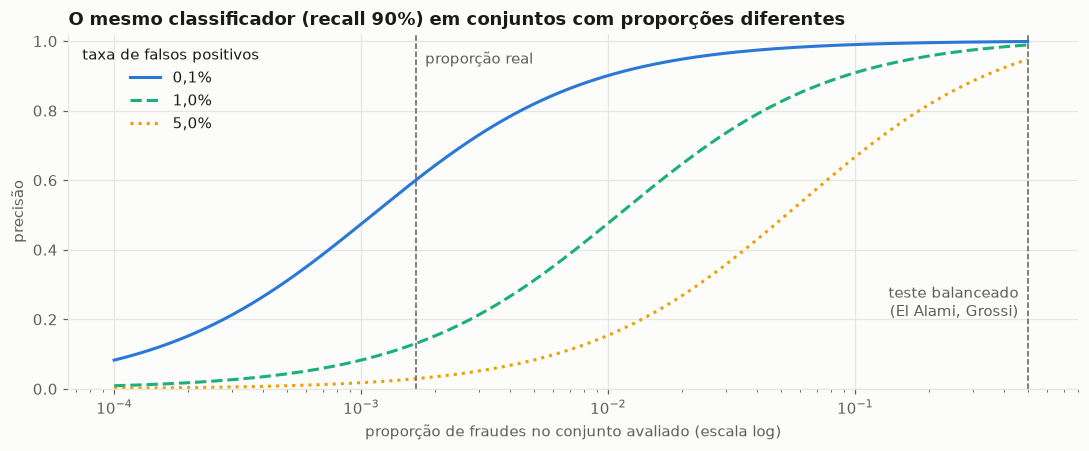

,teste 50/50,"proporção real (0,1667%)"
taxa de falsos positivos,,
0.1%,0.999,0.600
1.0%,0.989,0.131
5.0%,0.947,0.029


In [16]:
ILLUSTRATIVE_RECALL: float = 0.9
ILLUSTRATIVE_FALSE_POSITIVE_RATES: tuple[float, ...] = (0.001, 0.01, 0.05)
BALANCED_PREVALENCE: float = 0.5
FALSE_POSITIVE_STYLES: dict[float, dict[str, str]] = {
    0.001: {"color": "#2a78d6", "linestyle": "-"},
    0.01: {"color": "#1baf7a", "linestyle": "--"},
    0.05: {"color": "#eda100", "linestyle": ":"},
}

real_prevalence = clean_df[TARGET_COLUMN].mean()
prevalence_grid = np.logspace(-4, np.log10(BALANCED_PREVALENCE), 200)

fig, ax = plt.subplots(figsize=(10, 4.2))
for false_positive_rate, style in FALSE_POSITIVE_STYLES.items():
    precision_curve = precision_at_prevalence(ILLUSTRATIVE_RECALL, false_positive_rate, prevalence_grid)
    # Cor e estilo de linha diferentes por curva: a legenda não depende só da cor
    ax.plot(prevalence_grid, precision_curve, label=f"{false_positive_rate:.1%}".replace(".", ","), **style)
# Rótulos das linhas verticais onde não há curvas: no alto, à direita da proporção real; embaixo, à esquerda do 50/50
for prevalence, label, height, offset, alignment in (
    (real_prevalence, "proporção real", 0.97, 6, "left"),
    (BALANCED_PREVALENCE, "teste balanceado\n(El Alami, Grossi)", 0.3, -6, "right"),
):
    ax.axvline(prevalence, color="#5f5e58", linewidth=1, linestyle="--")
    ax.annotate(label, xy=(prevalence, height), xytext=(offset, 0), textcoords="offset points", ha=alignment, va="top",
                color="#5f5e58")
ax.legend(title="taxa de falsos positivos", loc="upper left")
ax.set_xscale("log")
ax.set_xlim(right=BALANCED_PREVALENCE * 1.6)
ax.set(title=f"O mesmo classificador (recall {ILLUSTRATIVE_RECALL:.0%}) em conjuntos com proporções diferentes",
       xlabel="proporção de fraudes no conjunto avaliado (escala log)", ylabel="precisão", ylim=(0, 1.02))
plt.tight_layout()
plt.show()

precision_by_prevalence = pd.DataFrame(
    {
        "teste 50/50": [float(precision_at_prevalence(ILLUSTRATIVE_RECALL, rate, BALANCED_PREVALENCE))
                        for rate in ILLUSTRATIVE_FALSE_POSITIVE_RATES],
        f"proporção real ({real_prevalence:.4%})".replace(".", ","): [float(precision_at_prevalence(ILLUSTRATIVE_RECALL, rate, real_prevalence))
                                                   for rate in ILLUSTRATIVE_FALSE_POSITIVE_RATES],
    },
    index=pd.Index([f"{rate:.1%}" for rate in ILLUSTRATIVE_FALSE_POSITIVE_RATES], name="taxa de falsos positivos"),
)
precision_by_prevalence.style.format("{:.3f}").set_caption(
    f"Precisão do mesmo classificador (recall {ILLUSTRATIVE_RECALL:.0%}) nas duas proporções"
)

### 3.3 O split

**Como.** O `train_test_split` do scikit-learn só divide em duas partes por chamada. O
`stratified_three_way_split` faz em dois estágios: primeiro separa o teste (20%); depois tira a validação do
restante, com a fração reescalada (0,2 / 0,8 = 25% do restante) para que cada parte tenha a fração pedida **da base
inteira**. Os dois estágios são estratificados pelo rótulo.

**Por que estratificar.** Com 473 fraudes, um sorteio simples de 20% dá, em média, 94,6 fraudes, mas pode dar
bem menos ou bem mais. A estratificação fixa a contagem de cada classe em cada parte (a menos de arredondamento).

**O que o `validate_split` verifica** (e lista todas as violações juntas, como o contrato da Seção 2):
- **disjunção:** nenhuma linha em duas partes;
- **cobertura:** a união das partes é exatamente a base;
- **tamanho** de cada parte e **contagem de cada classe**, a menos de 2 linhas (cada estágio arredonda no máximo
  1 linha por classe).

O split é feito nas **colunas originais**. As features dos modelos só são criadas na Seção 4, depois de a
exploração do treino dizer quais transformações fazem sentido. O índice original é preservado: cada linha continua
rastreável até o arquivo bruto. O `fingerprint` (hash dos índices de cada parte) vai para os resultados salvos, para
que números de sessões diferentes só sejam comparados quando o split for o mesmo.

In [17]:
SPLIT_LABELS: dict[str, str] = {TRAIN_NAME: "treino", VALIDATION_NAME: "validação", TEST_NAME: "teste"}
SPLIT_FRACTIONS: dict[str, float] = {
    TRAIN_NAME: config.TRAIN_SIZE, VALIDATION_NAME: config.VALIDATION_SIZE, TEST_NAME: config.TEST_SIZE
}

dataset_split = stratified_three_way_split(clean_df, random_state=config.RANDOM_STATE)
validate_split(clean_df, dataset_split)  # levanta SplitError listando todas as violações
split_parts = dataset_split.parts()
# Sufixo _raw: colunas originais. As features dos modelos são criadas na Seção 4, a partir do treino
train_raw_df, validation_raw_df, test_raw_df = dataset_split.train, dataset_split.validation, dataset_split.test

# As garantias centrais, explícitas no notebook (o validate_split já as verifica, junto com os tamanhos)
total_frauds = int(clean_df[TARGET_COLUMN].sum())
assert all(first.index.intersection(second.index).empty for first, second in combinations(split_parts.values(), 2)), \
    "linha em duas partes"
assert sum(len(part) for part in split_parts.values()) == len(clean_df), "linhas perdidas ou repetidas"
for name in (VALIDATION_NAME, TEST_NAME):
    # Nenhum balanceamento antes do split: validação e teste têm a fração esperada das fraudes, não a metade das linhas
    assert abs(split_parts[name][TARGET_COLUMN].sum() - SPLIT_FRACTIONS[name] * total_frauds) < STRATIFICATION_TOLERANCE_ROWS

# Nesta seção e na 4, de validação e teste só se contam linhas e rótulos e se fazem checagens de integridade
# (3.3.1). Nenhuma exploração sai deles: a validação só entra na Seção 5, para avaliar, e o teste, na Seção 9
print(f"Split válido. Fingerprint: {dataset_split.fingerprint()[:16]}…")

split_summary = pd.DataFrame(
    {
        "linhas": [len(part) for part in split_parts.values()],
        "fraudes": [int(part[TARGET_COLUMN].sum()) for part in split_parts.values()],
        "fraudes se a fração fosse exata": [SPLIT_FRACTIONS[name] * total_frauds for name in split_parts],
    },
    index=[SPLIT_LABELS[name] for name in split_parts],
)
split_summary.loc["base inteira"] = [len(clean_df), total_frauds, float(total_frauds)]
split_summary["% da base"] = split_summary["linhas"] / len(clean_df) * 100
split_summary["% de fraudes"] = split_summary["fraudes"] / split_summary["linhas"] * 100
split_summary.style.format(
    {"linhas": "{:,.0f}", "fraudes": "{:.0f}", "fraudes se a fração fosse exata": "{:.1f}",
     "% da base": "{:.1f}", "% de fraudes": "{:.4f}"}
).set_caption("Split estratificado 60/20/20 da base deduplicada")

Split válido. Fingerprint: 04d958c0d5744326…


,linhas,fraudes,fraudes se a fração fosse exata,% da base,% de fraudes
treino,"170,235",284,283.8,60.0,0.1668
validação,"56,745",94,94.6,20.0,0.1657
teste,"56,746",95,94.6,20.0,0.1674
base inteira,"283,726",473,473.0,100.0,0.1667


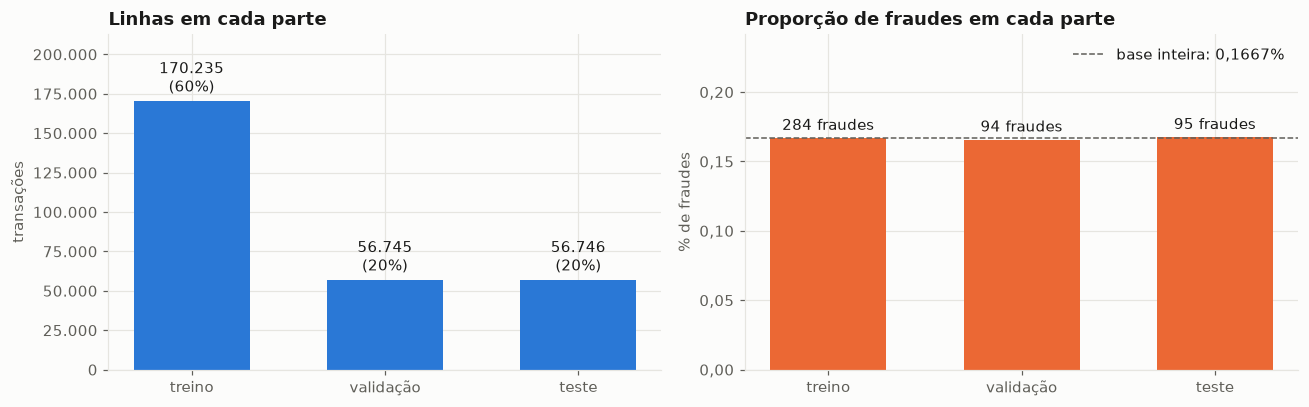

In [18]:
def brazilian_integer(value: int) -> str:
    """Inteiro com ponto como separador de milhar."""
    return f"{value:,}".replace(",", ".")


split_names = [SPLIT_LABELS[name] for name in split_parts]
fig, (rows_ax, rate_ax) = plt.subplots(1, 2, figsize=(12, 3.8))

row_bars = rows_ax.bar(split_names, split_summary.loc[split_names, "linhas"], color=NEUTRAL_SERIES_COLOR, width=0.6)
rows_ax.bar_label(row_bars, labels=[f"{brazilian_integer(int(n))}\n({share:.0f}%)" for n, share in
                                    split_summary.loc[split_names, ["linhas", "% da base"]].to_numpy()], padding=3)
rows_ax.set(title="Linhas em cada parte", ylabel="transações", ylim=(0, split_summary.loc["treino", "linhas"] * 1.25))

rate_bars = rate_ax.bar(split_names, split_summary.loc[split_names, "% de fraudes"], color=CLASS_COLORS[FRAUD_LABEL], width=0.6)
rate_ax.bar_label(rate_bars, labels=[f"{int(n)} fraudes" for n in split_summary.loc[split_names, "fraudes"]], padding=3)
rate_ax.axhline(real_prevalence * 100, color="#5f5e58", linewidth=1, linestyle="--",
                label=f"base inteira: {real_prevalence:.4%}".replace(".", ","))
rate_ax.legend(loc="upper right")
rate_ax.set(title="Proporção de fraudes em cada parte", ylabel="% de fraudes", ylim=(0, real_prevalence * 100 * 1.45))
rows_ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: brazilian_integer(int(value))))
rate_ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:.2f}".replace(".", ",")))
plt.tight_layout()
plt.show()

#### 3.3.1 Duas checagens de integridade do split

**Quase-duplicatas.** A Seção 3.1 removeu as linhas idênticas em **todas** as colunas. Sobram linhas iguais em
tudo menos o `Time`: a mesma compra (mesmas `V1`–`V28` e mesmo `Amount`) repetida em outro horário. Se uma cópia
fica no treino e outra na validação, o modelo seria avaliado numa transação praticamente já vista. A célula conta
quantos desses grupos atravessam o split e estima quantas dessas linhas chegam de fato ao treino **depois** do
undersampling, que é o que o modelo vê.

**Os dois dias da coleta.** O split é aleatório, não temporal: cada parte mistura transações dos dois dias. A
primeira tabela conta quantas linhas de cada dia caíram em cada parte; para isso lê o `Time` das três partes, e
nada mais delas. A segunda mostra como ficaria a alternativa, um split temporal 60/20/20, **simulado só com as
linhas de treino** ordenadas no tempo: as taxas de fraude por janela são exploração, e exploração só usa o treino.
A discussão está na leitura (3.4).

In [19]:
NEAR_DUPLICATE_KEY: list[str] = [*PCA_FEATURE_COLUMNS, "Amount"]
crossing = find_cross_split_groups(dataset_split, NEAR_DUPLICATE_KEY)

train_frauds = int(train_raw_df[TARGET_COLUMN].sum())
train_legitimate = len(train_raw_df) - train_frauds
# O undersampling sorteia tantas legítimas quanto há fraudes: cada legítima do treino tem essa chance de ser usada
legitimate_keep_probability = train_frauds / train_legitimate
expected_crossing_rows_seen = crossing.rows_by_split[TRAIN_NAME] * legitimate_keep_probability

print(f"Quase-duplicatas (mesmas V1–V28 e Amount) que atravessam o split: {crossing.groups:,} grupos, {crossing.rows:,} linhas")
print(f"  por classe: {crossing.rows_by_label}  |  por parte: {crossing.rows_by_split}")
print(f"  chance de uma legítima do treino sobreviver ao undersampling: {legitimate_keep_probability:.4%}")
print(f"  linhas desses grupos que o modelo vê no treino, em média: {expected_crossing_rows_seen:.1f}")

# Checagem de integridade: o Time das três partes é lido só para contar quantas linhas de cada dia caíram em cada uma
split_names = [SPLIT_LABELS[name] for name in split_parts]
collection_day = (clean_df["Time"] // SECONDS_PER_DAY).astype(int).add(1).rename("dia da coleta")
membership_labels = dataset_split.membership().map(SPLIT_LABELS)
day_mix = pd.crosstab(membership_labels, collection_day.loc[membership_labels.index], normalize="index") * 100
day_mix = day_mix.loc[split_names].rename(columns=lambda day: f"% das linhas do dia {day}")

# Como ficaria um split temporal 60/20/20, simulado SÓ com as linhas de treino ordenadas no tempo (CC12; não é usado)
TEMPORAL_WINDOWS: list[str] = ["primeiros 60% do tempo", "20% seguintes", "últimos 20%"]
time_ordered = train_raw_df.sort_values("Time", kind="stable")
temporal_bounds = [0, *(np.cumsum([config.TRAIN_SIZE, config.VALIDATION_SIZE]) * len(time_ordered)).astype(int),
                   len(time_ordered)]
temporal_parts = {name: time_ordered.iloc[start:end]
                  for name, start, end in zip(TEMPORAL_WINDOWS, temporal_bounds[:-1], temporal_bounds[1:])}
temporal_summary = pd.DataFrame(
    {
        "início (h)": [part["Time"].min() / SECONDS_PER_HOUR for part in temporal_parts.values()],
        "fim (h)": [part["Time"].max() / SECONDS_PER_HOUR for part in temporal_parts.values()],
        "fraudes": [int(part[TARGET_COLUMN].sum()) for part in temporal_parts.values()],
        "% de fraudes": [part[TARGET_COLUMN].mean() * 100 for part in temporal_parts.values()],
    },
    index=list(temporal_parts),
)
temporal_summary["duração (h)"] = temporal_summary["fim (h)"] - temporal_summary["início (h)"]

display(day_mix.style.format("{:.1f}").set_caption("Composição de cada parte por dia da coleta"))
temporal_summary.style.format("{:.1f}", subset=["início (h)", "fim (h)", "duração (h)"]).format(
    {"fraudes": "{:.0f}", "% de fraudes": "{:.4f}"}
).set_caption("Alternativa descartada: split temporal 60/20/20, simulado dentro do treino (horas desde a primeira transação)")

Quase-duplicatas (mesmas V1–V28 e Amount) que atravessam o split: 2,770 grupos, 8,960 linhas
  por classe: {0: 8960}  |  por parte: {'train': 4548, 'validation': 2194, 'test': 2218}
  chance de uma legítima do treino sobreviver ao undersampling: 0.1671%
  linhas desses grupos que o modelo vê no treino, em média: 7.6


dia da coleta,% das linhas do dia 1,% das linhas do dia 2
split,,
treino,50.7,49.3
validação,51.0,49.0
teste,51.1,48.9


,início (h),fim (h),fraudes,% de fraudes,duração (h)
primeiros 60% do tempo,0.000000,33.486667,199,0.1948,33.486667
20% seguintes,33.486944,40.377778,41,0.1204,6.890833
últimos 20%,40.378056,47.996667,44,0.1292,7.618611


### 3.4 Leitura dos resultados

**Duplicatas: removidas, e com mais motivo do que parecia.**
- Há 1.081 cópias extras. **3,9% das fraudes são cópias, contra 0,37% das legítimas**, ou seja, fraudes se repetem
  ~10× mais. Uma explicação plausível é a mesma cobrança fraudulenta registrada mais de uma vez.
- Nenhum grupo tem features iguais com rótulos diferentes, então a remoção não esconde nenhuma contradição.
- Num split 60/20/20, **56% dos pares duplicados** ficariam separados entre conjuntos. Sem a remoção, mais da metade
  das fraudes repetidas seria "testada" com uma cópia vista no treino.
- Resultado: 283.726 transações e 473 fraudes (0,1667%).

**A precisão depende da proporção de fraudes, e é por isso que o split vem antes do balanceamento.** O mesmo
classificador (recall 90%, 1% de falsos positivos) tem precisão **0,989** num teste 50/50 e **0,131** na proporção
real. Com 5% de falsos positivos, 0,947 contra 0,029. A precisão de 1,00 do El Alami (EA1), medida num teste 50/50, e
a acurácia do Grossi (GR1), num teste de ~52/48, não dizem nada sobre o cenário real.

**O split saiu como planejado.** 170.235 / 56.745 / 56.746 linhas (60,0 / 20,0 / 20,0%) e 284 / 94 / 95 fraudes. A
proporção de fraudes fica entre 0,1657% e 0,1674% nas três partes, contra 0,1667% na base inteira; o
`validate_split` e os `assert`s passaram.

**Quase-duplicatas existem, mas não contaminam.** 2.770 grupos (8.960 linhas) com as mesmas `V1`–`V28` e o mesmo
`Amount` atravessam o split, **todos de legítimas** (nenhuma fraude). O undersampling mantém 0,1671% das legítimas
do treino, então, em média, só 7,6 dessas linhas chegam ao modelo. Fica registrado (CC13); não há o que corrigir.

**O split aleatório mistura os dois dias, e o split temporal não seria melhor com estes dados.** Cada parte tem
entre 50,7% e 51,1% de linhas do dia 1. O split aleatório mede o desempenho em transações **do mesmo período** do
treino; um split temporal (treinar no passado, avaliar no futuro) mediria também a degradação ao longo do tempo. Com
48 horas de dados, porém, as janelas de validação e de teste seriam curtas e tardias. Simulado dentro do treino, um
split temporal 60/20/20 deixaria as duas últimas janelas com 6,9 e 7,6 horas (33,5–40,4 h e 40,4–48,0 h, isto é, da
manhã do dia 2 até a meia-noite): **nenhuma das duas cobriria a madrugada**, onde estão os picos de fraude (4.3).
Elas teriam 41 e 44 fraudes do treino, com taxas de 0,1204% e 0,1292%, contra 0,1948% nos primeiros 60% do tempo. A
diferença medida misturaria o horário com a passagem do tempo, sem separar um do outro. Além disso, o protocolo
aprovado e a literatura comparada usam o split aleatório estratificado. É uma limitação declarada (CC12): os
resultados não estimam a degradação ao longo do tempo.

**O que muda na Seção 4:** a exploração usa só as 170.235 linhas de treino (`train_raw_df`). De validação e teste,
até aqui, só foram lidos contagens e rótulos e feitas duas checagens de integridade: a de quase-duplicatas e a de
dias, que lê o `Time` das três partes só para contar linhas por dia.

## 4. Análise exploratória e pré-processamento (só no treino)

Tudo nesta seção usa **apenas as linhas de treino**. A seção tem duas partes:
- **4.1 a 4.5:** escalas, `Amount`, `Time` e as features que mais separam fraude de legítima. No meio, as
  transformações **linha a linha**, decididas aqui e aplicadas depois às três partes.
- **4.6 em diante:** escalonamento (Standard, Robust, MinMax), codificação quântica (ângulo × amplitude), seleção de
  features e undersampling, no **treino balanceado**, que é o que os modelos vão ver.

### O que sai daqui, e o que não sai
- **Sai:** decisões de desenho. Quais transformações linha a linha aplicar e quais opções entram no grid da Seção 6.
- **Não sai:** nenhum valor ajustado. Médias, eixos de PCA e features escolhidas aqui não são reaproveitados: o
  pipeline reajusta tudo em cada fold, e a escolha entre as opções é da validação cruzada.

O ranking de informação mútua, por exemplo, **mostra** quais features separam as classes, mas não **escolhe**
nenhuma. A seleção de features é refeita dentro do pipeline.

**Conhecimento prévio, declarado.** O Trabalho Humberto já explorou esta base inteira, e duas ideias vieram de
lá para o plano antes desta seção existir: o `log1p(Amount)` e a hora em seno/cosseno. Uma versão anterior deste
notebook também explorou a base inteira (CC7). Não dá para "desver" isso. O que esta seção garante é que cada
número e cada justificativa do TCC saem **só do treino**, e que nenhum valor ajustado fora do pipeline chega aos
modelos.

### 4.1 Escalas e caudas

Antes de qualquer transformação, a pergunta é em que escala cada variável chega. Métodos que medem distância ou
variância (SVM com kernel RBF, kernels quânticos, PCA) são dominados pela variável de maior escala, e um único
valor extremo muda o mínimo ou o máximo de uma coluna inteira.

**Os termos da tabela:**
- **Média:** a soma dos valores dividida pela quantidade.
- **Desvio padrão** (*standard deviation*, abreviado *std* nas bibliotecas): o tamanho típico da distância de cada
  valor até a média. Conta: subtrai a média de cada valor, eleva ao quadrado, tira a média desses quadrados e a
  raiz. Exemplo: os valores 2, 4, 4, 4, 5, 5, 7 e 9 têm média 5 e desvio padrão 2; os valores 1, 9, 2 e 8 têm a
  mesma média e desvio padrão 3,54, porque estão mais espalhados. É a "escala" de uma coluna.
- **Mínimo e máximo:** o menor e o maior valor da coluna.
- **Extremo, em desvios da média:** a que distância da média fica o valor mais afastado dela, medida em desvios
  padrão. Numa distribuição normal, passar de 4 ou 5 desvios já é raríssimo; valores muito acima disso indicam uma
  **cauda longa**, isto é, alguns pontos muito distantes do resto.

Os dois maiores valores das colunas de desvio padrão e de extremo aparecem destacados em ciano escuro.

**Todas as 30 colunas de entrada, e não algumas escolhidas.** Uma versão anterior desta análise mostrava `Time`,
`Amount`, `V1` e `V14`. A `V14` estava ali porque já sabíamos, da base inteira e do trabalho anterior, que ela separa
fraudes: escolher o que olhar a partir desse conhecimento é a mesma falha do CC7 em escala menor. E a escolha mudava
o resultado: a razão de escala entre `Time` e "as `V`" dependia de qual `V` entrava no denominador (NC12). Daqui em
diante, a exploração mostra todas as colunas ou seleciona a partir de uma saída já calculada no treino (como o
ranking da 4.5).

In [20]:
# Nomes das estatísticas em português: o leitor não precisa conhecer as abreviações do pandas (mean, std...)
SCALE_STATISTICS: dict[str, str] = {"mean": "média", "std": "desvio padrão", "min": "mínimo", "max": "máximo"}
EXTREME_COLUMN: str = "extremo (desvios da média)"
# Ciano escuro com texto branco fixo: não é o azul das legítimas nem o laranja das fraudes, e o contraste (7,3:1) não
# depende do tema do editor. Sem fixar o texto, o tema claro poria texto preto sobre o fundo escuro (2,4:1)
HIGHLIGHT_COLOR: str = "#006161"
HIGHLIGHT_TEXT_COLOR: str = "#ffffff"
HIGHLIGHTED_PER_COLUMN: int = 2

# Todas as colunas de entrada, na ordem do arquivo: nenhuma escolhida a partir do que já se sabia da base inteira
train_scales = train_raw_df[list(RAW_FEATURE_COLUMNS)].describe().T[list(SCALE_STATISTICS)].rename(columns=SCALE_STATISTICS)
# A que distância da média (em desvios padrão) fica o valor mais extremo de cada coluna: mede o peso da cauda
train_scales[EXTREME_COLUMN] = (
    np.maximum((train_scales["máximo"] - train_scales["média"]).abs(), (train_scales["mínimo"] - train_scales["média"]).abs())
    / train_scales["desvio padrão"]
)
v_std = train_scales.loc[list(PCA_FEATURE_COLUMNS), "desvio padrão"]
v_extreme = train_scales.loc[list(PCA_FEATURE_COLUMNS), EXTREME_COLUMN]
train_pca_values = train_raw_df[list(PCA_FEATURE_COLUMNS)]

print(f"Treino: {len(train_raw_df):,} linhas, {train_frauds} fraudes")
print(f"Desvio padrão das 28 V: de {v_std.min():.2f} ({v_std.idxmin()}) a {v_std.max():.2f} ({v_std.idxmax()})")
for column in ("Time", "Amount"):
    column_std = train_scales.loc[column, "desvio padrão"]
    print(f"Desvio padrão de {column} ÷ desvio padrão das V: de {column_std / v_std.max():,.0f}× a {column_std / v_std.min():,.0f}×")
print(f"Faixa de V1–V28 no treino: [{train_pca_values.min().min():,.1f}; {train_pca_values.max().max():,.1f}]")
print(f"Valor mais extremo de cada V: de {v_extreme.min():.0f} a {v_extreme.max():.0f} desvios da média "
      f"(mediana {v_extreme.median():.0f}); em {(v_extreme > 10).sum()} das 28 passa de 10")
print(f"Período coberto pelo treino: {train_raw_df['Time'].max() / SECONDS_PER_HOUR:.1f} horas")


def highlight_largest(column: pd.Series) -> list[str]:
    """Destaque (fundo ciano escuro, texto branco) nos maiores valores da coluna."""
    largest = column.nlargest(HIGHLIGHTED_PER_COLUMN).index
    style = f"background-color: {HIGHLIGHT_COLOR}; color: {HIGHLIGHT_TEXT_COLOR}"
    return [style if row in largest else "" for row in column.index]


train_scales.style.format("{:,.2f}").apply(highlight_largest, subset=["desvio padrão", EXTREME_COLUMN]).set_caption(
    "Escala das 30 colunas de entrada, no treino (destaque: os 2 maiores desvios padrão e as 2 caudas mais extremas)"
)

Treino: 170,235 linhas, 284 fraudes
Desvio padrão das 28 V: de 0.33 (V28) a 1.95 (V1)
Desvio padrão de Time ÷ desvio padrão das V: de 24,345× a 142,653×
Desvio padrão de Amount ÷ desvio padrão das V: de 126× a 740×
Faixa de V1–V28 no treino: [-73.2; 39.4]
Valor mais extremo de cada V: de 6 a 102 desvios da média (mediana 20); em 23 das 28 passa de 10
Período coberto pelo treino: 48.0 horas


,média,desvio padrão,mínimo,máximo,extremo (desvios da média)
Time,"94,935.86","47,513.48",0.00,"172,788.00",2.00
V1,0.00,1.95,-56.41,2.45,28.90
V2,-0.01,1.66,-72.72,21.47,43.85
V3,0.00,1.50,-31.81,9.38,21.15
V4,-0.00,1.42,-5.60,16.88,11.90
V5,0.01,1.36,-32.09,34.80,25.56
V6,-0.00,1.32,-26.16,21.39,19.77
V7,0.00,1.20,-41.51,34.30,34.63
V8,0.00,1.17,-73.22,19.59,62.69
V9,-0.00,1.10,-13.43,15.59,14.24


### 4.2 `Amount`: o valor da transação

Duas perguntas guiam a análise:
- `Amount` é assimétrica, a ponto de pedir uma transformação?
- Fraude e legítima têm valores diferentes?

**Os termos da tabela.** Cada coluna descreve **só as transações de uma classe** (legítimas ou fraudes).
- **Média:** a soma dos valores dividida pela quantidade.
- **Mediana:** o valor do meio. Metade das transações tem valor abaixo dela, e metade acima. Ao contrário da média,
  ela não é puxada por poucos valores muito altos.
- **Percentil:** o percentil *p* é o valor abaixo do qual ficam *p*% dos dados. A mediana é o percentil 50. Exemplo
  com os dados: o percentil 99 das legítimas é 1.008,99, então 99% das legítimas têm valor de até 1.008,99, e só 1%
  passa disso.
- **As porcentagens são de cada classe, e não da base.** "% com valor = 0" na coluna "fraude" é a fração **das
  fraudes** cujo `Amount` é zero; na coluna "legítima", a fração das legítimas.
- **Assimetria** (*skewness*): mede o quanto a distribuição pende para um lado. Zero é simétrica; um valor positivo
  indica uma cauda longa à direita, isto é, poucos valores muito altos e a maioria baixa.

**Por que o gráfico da esquerda corta o eixo no percentil 99.** O maior valor do treino é 19.656,53. Com o eixo indo
até ele, cada uma das 60 barras do histograma teria 328 de largura, e 94,3% das transações cairiam na primeira
barra: o gráfico viraria uma barra só. Cortando no percentil 99, o eixo mostra o formato onde estão 99% dos dados.
Os valores acima do corte **não são descartados**: ficam empilhados na última barra (o pico na borda direita).
- O corte é o **maior** dos percentis 99 das duas classes (1.391,70, o das fraudes), e não o do treino inteiro
  (1.011,16). Como 99,8% das linhas são legítimas, o percentil do treino inteiro é, na prática, o das legítimas, e
  empilharia 1,76% das fraudes na borda, em vez de 1,06%.
- 99, e não 95 ou 99,9, é um compromisso: mostra quase todos os dados e tira só a cauda extrema. Nenhuma conclusão
  depende desse número, e o gráfico da direita, em escala log, não precisa de corte: comprimir a cauda é justamente
  o que o `log1p` faz.

As distribuições são comparadas por **densidade** (proporção dentro de cada classe), e não por contagem. Com
centenas de legítimas para cada fraude, um histograma de contagens mostraria só as legítimas.

In [21]:
def amount_profile(amounts: pd.Series) -> dict[str, float]:
    """Resumo de uma distribuição de valores, com foco na cauda e nos valores muito baixos.

    Os rótulos são frases, e não abreviações, para a tabela ser lida sem conhecer os termos de antemão.
    """
    return {
        "valor médio (média)": amounts.mean(),
        "valor do meio (mediana: metade abaixo, metade acima)": amounts.median(),
        "percentil 99 (99% das transações têm valor até aqui)": amounts.quantile(0.99),
        "maior valor": amounts.max(),
        "% das transações com valor = 0": (amounts == 0).mean() * 100,
        "% das transações com valor até 1,00": (amounts <= 1).mean() * 100,
        "% das transações com valor = 1,00": (amounts == 1).mean() * 100,
        "% das transações com valor = 99,99": (amounts == 99.99).mean() * 100,
        "assimetria (0 = simétrica; positiva = cauda longa à direita)": amounts.skew(),
    }


pd.DataFrame(
    {CLASS_NAMES[label]: amount_profile(group["Amount"]) for label, group in train_raw_df.groupby(TARGET_COLUMN)}
).style.format("{:,.2f}").set_caption(
    "Valor da transação (Amount) por classe, no treino. Cada coluna descreve só as transações daquela classe, "
    "e cada % é sobre a própria classe"
)

,legítima,fraude
valor médio (média),88.11,118.87
"valor do meio (mediana: metade abaixo, metade acima)",22.05,11.86
percentil 99 (99% das transações têm valor até aqui),"1,008.99","1,391.70"
maior valor,"19,656.53","2,125.87"
% das transações com valor = 0,0.63,5.28
"% das transações com valor até 1,00",10.61,33.45
"% das transações com valor = 1,00",4.72,21.48
"% das transações com valor = 99,99",0.10,6.34
assimetria (0 = simétrica; positiva = cauda longa à direita),15.22,4.16


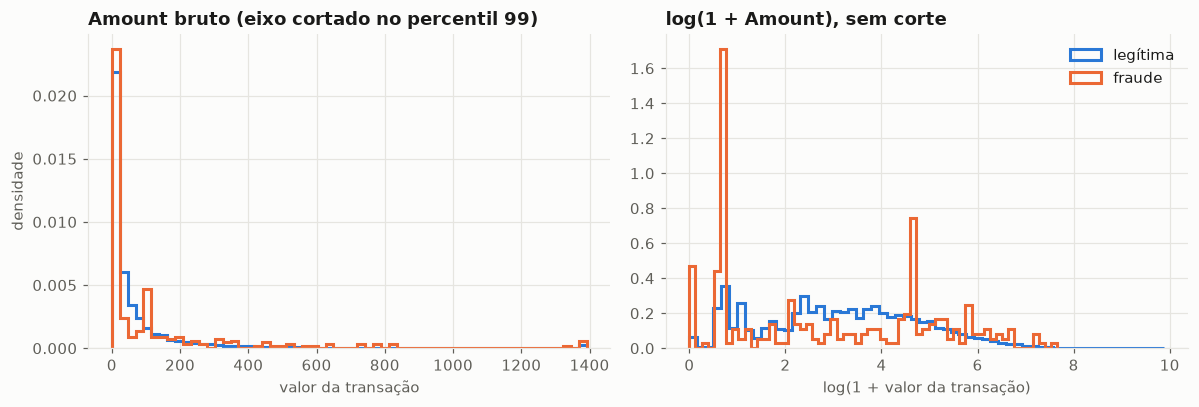

In [22]:
fig, (raw_ax, log_ax) = plt.subplots(1, 2, figsize=(11, 3.8))
# Corte no MAIOR percentil 99 entre as classes: o percentil do treino inteiro é, na prática, o das legítimas,
# e empilharia parte das fraudes na borda do gráfico
amount_clip = train_raw_df.groupby(TARGET_COLUMN)["Amount"].quantile(0.99).max()

for label, group in train_raw_df.groupby(TARGET_COLUMN):
    style = {"color": CLASS_COLORS[label], "label": CLASS_NAMES[label], "histtype": "step", "linewidth": 2, "density": True}
    raw_ax.hist(group["Amount"].clip(upper=amount_clip), bins=60, **style)
    log_ax.hist(np.log1p(group["Amount"]), bins=60, **style)

raw_ax.set(title="Amount bruto (eixo cortado no percentil 99)", xlabel="valor da transação", ylabel="densidade")
log_ax.set(title="log(1 + Amount), sem corte", xlabel="log(1 + valor da transação)")
log_ax.legend()
plt.tight_layout()
plt.show()

### 4.3 `Time`: de segundos corridos para hora do dia

`Time` conta segundos desde a primeira transação, ao longo de dois dias. O que pode se repetir no futuro é a
**hora do dia**, e não o "segundo 93.000 da coleta".

O dataset não informa a que horas foi a primeira transação. A conversão supõe que `Time = 0` é meia-noite, e o
volume por hora permite checar essa suposição: se ela estiver certa, o vale de movimento cai na madrugada.

Os dois gráficos têm medidas diferentes (contagem e taxa). Por isso ficam em painéis separados, e não em dois eixos
y no mesmo gráfico. A última célula compara a taxa de fraude entre os dois dias da coleta.

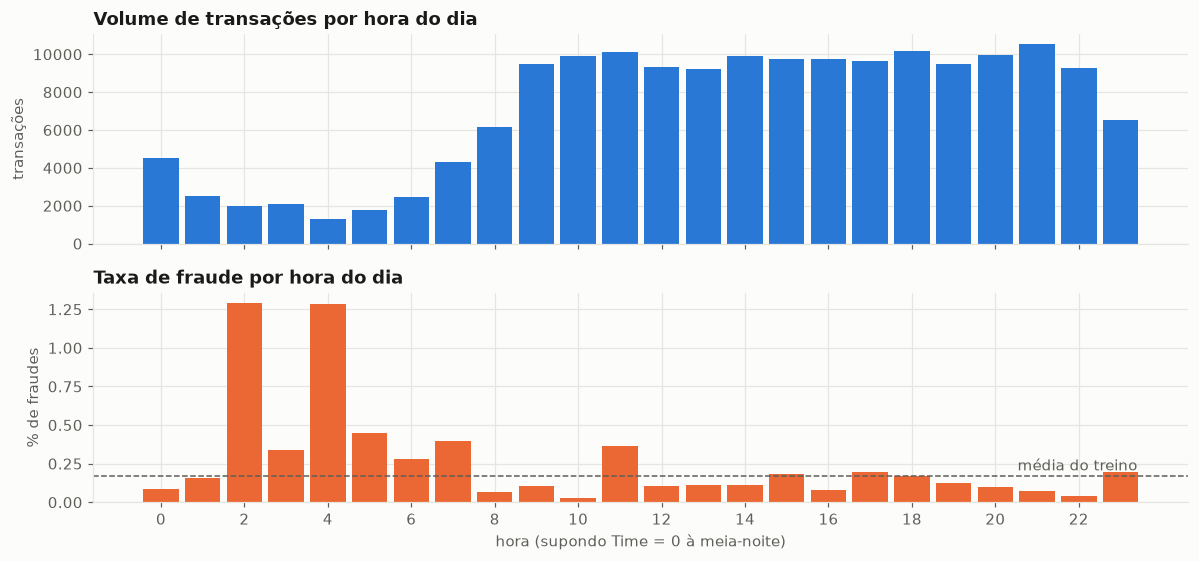

,transações,fraudes,taxa de fraude (%)
hour,,,
2,2012,26,1.29
4,1325,17,1.28
5,1785,8,0.45
7,4308,17,0.39


In [23]:
train_fraud_rate_percent = train_frauds / len(train_raw_df) * 100
hourly = (
    train_raw_df.assign(hour=np.floor(hour_of_day(train_raw_df["Time"])).astype(int))
    .groupby("hour")[TARGET_COLUMN]
    .agg(transações="size", fraudes="sum")
)
hourly["taxa de fraude (%)"] = hourly["fraudes"] / hourly["transações"] * 100

fig, (volume_ax, rate_ax) = plt.subplots(2, 1, figsize=(11, 5.2), sharex=True)
volume_ax.bar(hourly.index, hourly["transações"], color=NEUTRAL_SERIES_COLOR, width=0.85)
volume_ax.set(title="Volume de transações por hora do dia", ylabel="transações")
rate_ax.bar(hourly.index, hourly["taxa de fraude (%)"], color=CLASS_COLORS[FRAUD_LABEL], width=0.85)
rate_ax.axhline(train_fraud_rate_percent, color="#5f5e58", linewidth=1, linestyle="--")
rate_ax.annotate("média do treino", xy=(23.4, train_fraud_rate_percent),
                 xytext=(0, 4), textcoords="offset points", ha="right", color="#5f5e58")
rate_ax.set(title="Taxa de fraude por hora do dia", xlabel="hora (supondo Time = 0 à meia-noite)", ylabel="% de fraudes")
rate_ax.set_xticks(range(0, 24, 2))
plt.tight_layout()
plt.show()

hourly.sort_values("taxa de fraude (%)", ascending=False).head(4).style.format(
    {"taxa de fraude (%)": "{:.2f}"}
).set_caption("As 4 horas com maior taxa de fraude, no treino")

#### hour_sin e hour_cos: o relógio

A hora vira um ponto num círculo, como o ponteiro de um relógio. São necessárias **duas** coordenadas:
- **Só com o seno**, horas diferentes colidem. Por exemplo, 3h e 9h têm o mesmo seno (0,71), e 0h e 12h também
  (0). O modelo não conseguiria distingui-las.
- **Com seno e cosseno juntos**, cada hora tem um par único. Horas vizinhas ficam sempre à mesma distância,
  inclusive 23h e 0h.

Os gráficos mostram as duas curvas ao longo do dia e o círculo resultante. No círculo, o tamanho de cada ponto é
proporcional à taxa de fraude daquela hora.

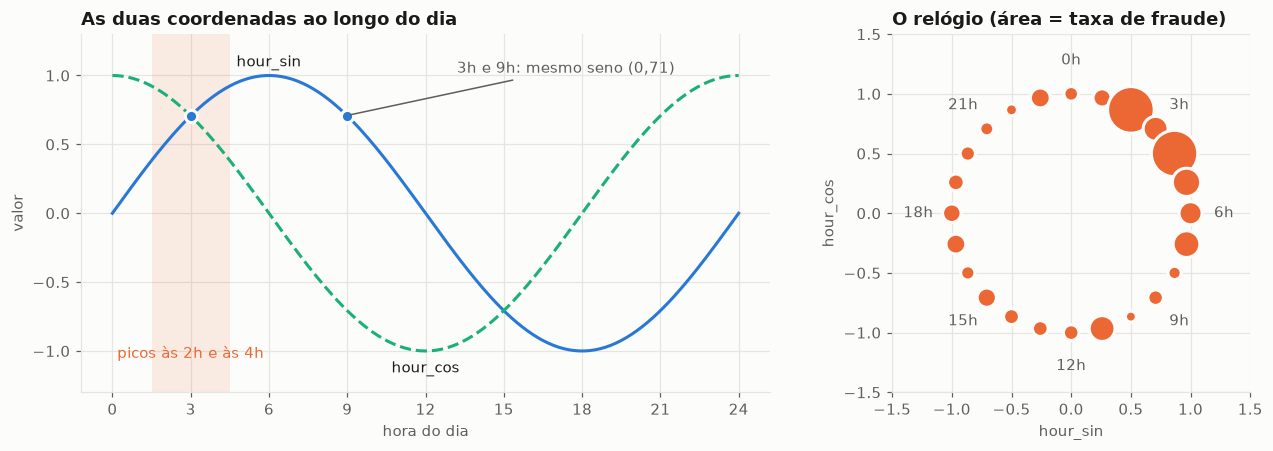

In [24]:
SIN_COLOR, COS_COLOR = NEUTRAL_SERIES_COLOR, "#1baf7a"
hours_grid = np.linspace(0, 24, 241)
grid_angle = 2 * np.pi * hours_grid / 24

fig, (curve_ax, clock_ax) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})

curve_ax.axvspan(1.5, 4.5, color=CLASS_COLORS[FRAUD_LABEL], alpha=0.12, linewidth=0)
curve_ax.annotate("picos às 2h e às 4h", xy=(3, -1.05), ha="center", color=CLASS_COLORS[FRAUD_LABEL])
curve_ax.plot(hours_grid, np.sin(grid_angle), color=SIN_COLOR)
curve_ax.plot(hours_grid, np.cos(grid_angle), color=COS_COLOR, linestyle="--")
# Rótulos diretos nas curvas: a identificação não depende só da cor
curve_ax.annotate("hour_sin", xy=(6, 1), xytext=(0, 6), textcoords="offset points", ha="center", color="#1a1a19")
curve_ax.annotate("hour_cos", xy=(12, -1), xytext=(0, -14), textcoords="offset points", ha="center", color="#1a1a19")
# A colisão que torna o seno sozinho insuficiente: 3h e 9h têm o mesmo seno
for colliding_hour in (3, 9):
    curve_ax.plot(colliding_hour, np.sin(2 * np.pi * colliding_hour / 24), "o", markersize=8,
                  color=SIN_COLOR, markeredgecolor="#fcfcfb", markeredgewidth=2)
curve_ax.annotate("3h e 9h: mesmo seno (0,71)", xy=(9, 0.71), xytext=(13.2, 1.02), color="#5f5e58",
                  arrowprops={"arrowstyle": "-", "color": "#5f5e58", "linewidth": 1})
curve_ax.set(title="As duas coordenadas ao longo do dia", xlabel="hora do dia", ylabel="valor", ylim=(-1.3, 1.3))
curve_ax.set_xticks(range(0, 25, 3))

# Relógio: x = seno e y = cosseno põe 0h no topo e as horas no sentido horário
integer_hours = hourly.index.to_numpy()
hour_angle = 2 * np.pi * integer_hours / 24
marker_area = 30 + 900 * hourly["taxa de fraude (%)"] / hourly["taxa de fraude (%)"].max()
clock_ax.scatter(np.sin(hour_angle), np.cos(hour_angle), s=marker_area, color=CLASS_COLORS[FRAUD_LABEL],
                 edgecolor="#fcfcfb", linewidth=2, zorder=3)
for hour in range(0, 24, 3):
    angle = 2 * np.pi * hour / 24
    clock_ax.annotate(f"{hour}h", xy=(1.28 * np.sin(angle), 1.28 * np.cos(angle)), ha="center", va="center",
                      color="#5f5e58")
clock_ax.set(title="O relógio (área = taxa de fraude)", xlabel="hour_sin", ylabel="hour_cos",
             xlim=(-1.5, 1.5), ylim=(-1.5, 1.5), aspect="equal")
plt.tight_layout()
plt.show()

In [25]:
train_day = collection_day.loc[train_raw_df.index]
fraud_by_day = train_raw_df.groupby(train_day)[TARGET_COLUMN].agg(transações="count", fraudes="sum")
fraud_by_day["% de fraudes"] = fraud_by_day["fraudes"] / fraud_by_day["transações"] * 100
_, day_p_value, _, _ = chi2_contingency(pd.crosstab(train_day, train_raw_df[TARGET_COLUMN]))
day_rate_ratio = fraud_by_day.loc[2, "% de fraudes"] / fraud_by_day.loc[1, "% de fraudes"]
print(f"Taxa de fraude do dia 2 ÷ dia 1 (treino): {day_rate_ratio:.2f}; teste qui-quadrado, p = {day_p_value:.4f}")

# Padrão ou episódio? Fraudes de cada dia nas horas de maior taxa: um pico que só existe num dos dias é um episódio
PEAK_HOURS_SHOWN: int = 5
peak_hours = sorted(hourly["taxa de fraude (%)"].nlargest(PEAK_HOURS_SHOWN).index)
is_train_fraud = train_raw_df[TARGET_COLUMN] == FRAUD_LABEL
train_hour = np.floor(hour_of_day(train_raw_df["Time"])).astype(int).rename("hora")
peak_by_day = pd.crosstab(train_hour[is_train_fraud], train_day[is_train_fraud]).reindex(peak_hours, fill_value=0)
peak_by_day.columns = [f"fraudes no dia {day}" for day in peak_by_day.columns]

display(peak_by_day.style.set_caption(f"Fraudes do treino por dia, nas {PEAK_HOURS_SHOWN} horas de maior taxa de fraude"))
fraud_by_day.style.format({"transações": "{:,.0f}", "fraudes": "{:.0f}", "% de fraudes": "{:.4f}"}).set_caption(
    "Fraudes por dia da coleta, no treino"
)

Taxa de fraude do dia 2 ÷ dia 1 (treino): 0.81; teste qui-quadrado, p = 0.0848


,fraudes no dia 1,fraudes no dia 2
hora,,
2,11,15
4,5,12
5,8,0
7,17,0
11,28,9


,transações,fraudes,% de fraudes
dia da coleta,,,
1,"86,311",159,0.1842
2,"83,924",125,0.1489


### 4.4 Transformações linha a linha

O que as duas análises acima pedem:

| Transformação | De → para | Por quê |
|---|---|---|
| `amount_log = log(1 + Amount)` | `Amount` → `amount_log` | Comprime a cauda longa. É `log1p` porque há valores zero, e log(0) não existe |
| `hour_sin`, `hour_cos` | `Time` → hora do dia no círculo | 23h59 e 00h00 ficam vizinhas. `Time` bruto descreve os dois dias da coleta, não um padrão repetível |

As duas já estavam previstas no plano, vindas do trabalho anterior; o que as **justifica** aqui são as análises
do treino acima. Elas são **aplicadas** às três partes. Aplicá-las à validação e ao
teste não é vazamento: cada linha é transformada só com os próprios valores, por uma função fixa, sem nenhum
parâmetro ajustado.

`Amount` e `hour_of_day` continuam na tabela como colunas **auxiliares**: servem para gráficos e para o modelo de
custo do limiar (Seção 7), mas **nunca** entram nos modelos. As verificações abaixo garantem isso.

In [26]:
train_df, validation_df, test_df = (
    engineer_features(part) for part in (train_raw_df, validation_raw_df, test_raw_df)
)
X_train, y_train = train_df[list(MODEL_FEATURE_COLUMNS)], train_df[TARGET_COLUMN]
X_validation, y_validation = validation_df[list(MODEL_FEATURE_COLUMNS)], validation_df[TARGET_COLUMN]
# O teste não é separado em X/y aqui: ele só é usado para avaliar, na Seção 9

for engineered, original in ((train_df, train_raw_df), (validation_df, validation_raw_df), (test_df, test_raw_df)):
    assert engineered.index.equals(original.index), "a transformação não pode mudar nem reordenar linhas"
    assert not engineered[list(MODEL_FEATURE_COLUMNS)].isna().any().any()
assert len(MODEL_FEATURE_COLUMNS) == 31 and "Time" not in MODEL_FEATURE_COLUMNS
assert not set(AUXILIARY_COLUMNS) & set(MODEL_FEATURE_COLUMNS), "coluna auxiliar vazando para os modelos"

pd.DataFrame(
    {
        "assimetria antes": [train_raw_df["Amount"].skew()],
        "assimetria depois": [train_df["amount_log"].skew()],
    },
    index=["Amount → amount_log (treino)"],
).style.format("{:.2f}").set_caption("Assimetria de Amount antes e depois do log1p, no treino")

,assimetria antes,assimetria depois
Amount → amount_log (treino),15.20,0.16


### 4.5 Quais features separam fraude de legítima

Duas medidas de associação com o rótulo, com papéis diferentes:
- **Correlação de Pearson:** mede relação **linear**, de −1 a 1. Se as fraudes ficam nas duas pontas de uma feature
  (valores muito altos *e* muito baixos), os efeitos se cancelam e a correlação fica perto de zero.
- **Informação mútua (MI, de *mutual information*):** mede **qualquer** dependência. Responde "quanto saber o valor
  da feature reduz a incerteza sobre o rótulo?". É zero só quando feature e rótulo são independentes. A unidade é o
  **nat** (a mesma ideia do bit, com logaritmo natural no lugar do logaritmo na base 2); o que importa aqui é a
  comparação entre as features, e não o valor absoluto.

O ranking é calculado **no treino** e é descritivo: orienta quais opções entram no grid, mas a seleção de features
de verdade é refeita dentro do pipeline, em cada fold.

As features analisadas são as 31 que entram nos modelos (4.4): `V1`–`V28`, `amount_log`, `hour_sin` e `hour_cos`.

**Os três resultados abaixo:**
1. **A tabela** traz as 31 features, com a informação mútua, a correlação de Pearson e a posição no ranking.
2. **O gráfico de barras** mostra as mesmas 31, ordenadas, para ver de relance onde o sinal se concentra.
3. **As distribuições por classe** das 4 features de maior informação mútua no treino. São 4 porque é o que cabe numa
   linha de painéis com resolução suficiente; a escolha sai do ranking do treino, e não do que já se sabia da base
   (a regra contra vazamento por conhecimento prévio, NC12). Elas mostram o **formato** do sinal que o ranking resume num número.

**Por que o eixo das distribuições é cortado nos percentis 1 e 99.** É só para o **desenho**: os dados não mudam, e o
modelo recebe todos os valores.
- As `V` têm caudas longas (4.1). Num histograma, o eixo vai do menor ao maior valor, então meia dúzia de pontos
  extremos esticam o eixo, e as legítimas, que formam um pico estreito perto de zero, ficam espremidas em pouquíssimas
  barras. Cortar o eixo mostra o formato onde estão quase todos os dados.
- O corte é **por classe**: vai do **menor** percentil 1 ao **maior** percentil 99 entre as duas classes. O percentil
  do treino inteiro seria, na prática, o das legítimas (99,8% das linhas) e cortaria justamente a cauda das fraudes,
  que é o sinal (o erro registrado no NC2).
- A tabela depois do gráfico mostra, para cada painel, o eixo com e sem corte, quantas barras o pico das legítimas
  ocupa em cada caso e o que fica fora do desenho.
- **Isso não é tratamento de dados.** Cortar valores extremos nos próprios dados tem nome (*winsorização*) e não é
  feito aqui: neste problema os extremos são justamente onde estão as fraudes. O único corte que o modelo vê é o
  `clip=True` do MinMax, que segura na borda um valor da validação ou do teste fora da faixa do treino (4.7.1).

In [27]:
with CostMeter(trace_python_memory=False) as mi_meter:
    mutual_information = mutual_info_classif(X_train, y_train, random_state=config.RANDOM_STATE, n_jobs=config.N_JOBS)

association = pd.DataFrame(
    {
        "informação mútua": mutual_information,
        "correlação de Pearson": X_train.corrwith(y_train),
    },
    index=MODEL_FEATURE_COLUMNS,
).sort_values("informação mútua", ascending=False)
association["posição (MI)"] = range(1, len(association) + 1)
print(f"Informação mútua em {len(X_train):,} linhas de treino: {mi_meter.report.wall_seconds:.1f} s")
association.style.format({"informação mútua": "{:.4f}", "correlação de Pearson": "{:.3f}"}).set_caption(
    "Associação de cada feature com o rótulo, no treino (ordenada pela informação mútua)"
)

Informação mútua em 170,235 linhas de treino: 10.8 s


,informação mútua,correlação de Pearson,posição (MI)
V17,0.0079,-0.320,1
V14,0.0079,-0.299,2
V10,0.0071,-0.208,3
V12,0.0071,-0.251,4
V11,0.0063,0.151,5
V16,0.0058,-0.187,6
V3,0.0046,-0.189,7
V4,0.0046,0.127,8
V9,0.0040,-0.093,9
V18,0.0039,-0.105,10


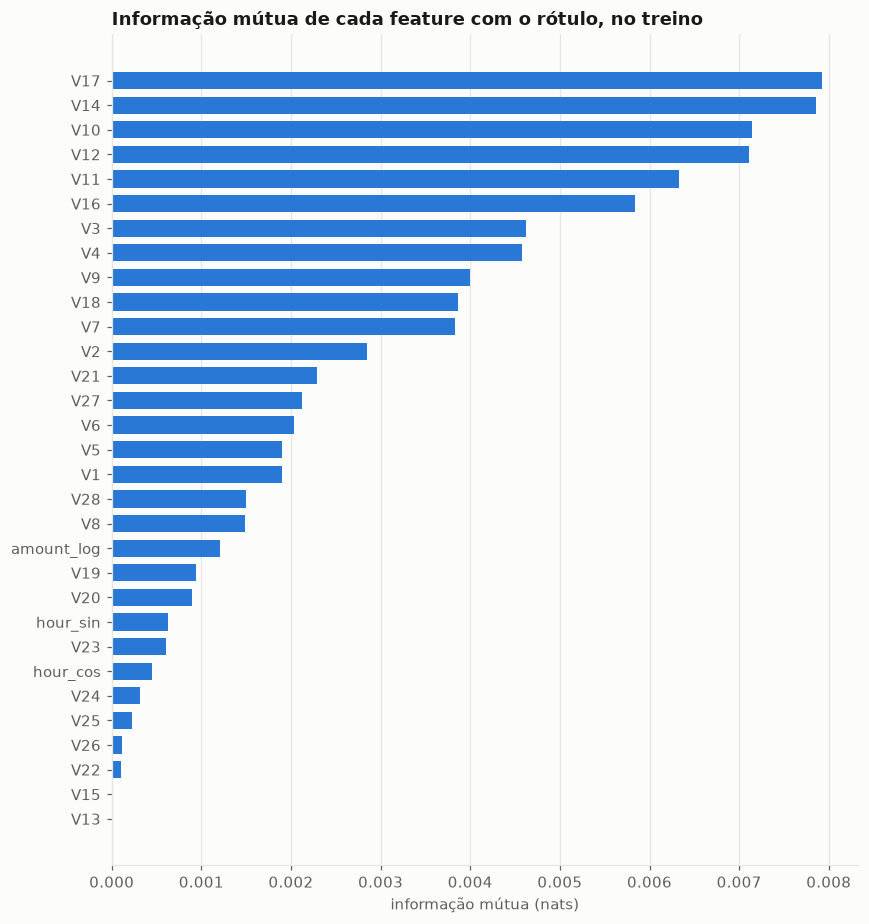

In [28]:
# Todas as 31 features, da maior para a menor informação mútua (a de cima é a maior)
ranked_association = association.iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 8.5))
ax.barh(ranked_association.index, ranked_association["informação mútua"], color=NEUTRAL_SERIES_COLOR, height=0.7)
ax.set(title="Informação mútua de cada feature com o rótulo, no treino", xlabel="informação mútua (nats)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

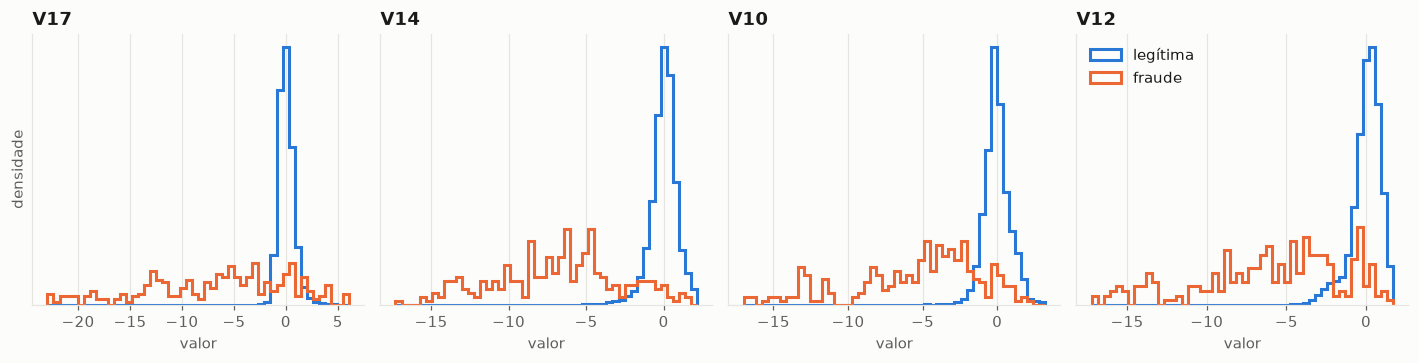

,eixo sem corte,eixo com corte,"barras do pico das legítimas, sem corte","barras do pico das legítimas, com corte",% das legítimas fora do desenho,fraudes fora do desenho
feature,,,,,,
V17,-24.0 a 9.3,-22.9 a 6.1,3.4,3.9,0.01,6
V14,-19.2 a 10.5,-17.3 a 2.1,4.7,7.2,1.00,3
V10,-24.4 a 23.7,-17.0 a 3.2,3.0,7.1,1.00,5
V12,-18.6 a 7.8,-17.2 a 1.7,6.0,8.4,1.00,3


In [29]:
# Distribuição por classe das 4 features de maior informação mútua no treino. O eixo de cada painel é cortado no
# menor percentil 1 e no maior percentil 99 ENTRE AS CLASSES: cortar pelos percentis do treino inteiro jogaria parte
# das fraudes (0,17% das linhas) para fora do intervalo. O corte é só do desenho; os dados não mudam
DISTRIBUTION_FEATURES: int = 4
HISTOGRAM_BINS: int = 50
top_features = association.index[:DISTRIBUTION_FEATURES]
is_train_legitimate = train_df[TARGET_COLUMN] == LEGITIMATE_LABEL

cut_effect_rows: list[dict[str, str | float | int]] = []
fig, axes = plt.subplots(1, len(top_features), figsize=(13, 3.4))
for ax, feature in zip(axes, top_features):
    class_quantiles = train_df.groupby(TARGET_COLUMN)[feature].quantile([0.01, 0.99]).unstack()
    low, high = class_quantiles[0.01].min(), class_quantiles[0.99].max()
    bins = np.linspace(low, high, HISTOGRAM_BINS + 1)
    for label, group in train_df.groupby(TARGET_COLUMN):
        inside = group[feature].between(low, high)
        ax.hist(group.loc[inside, feature], bins=bins, density=True, histtype="step", linewidth=2,
                color=CLASS_COLORS[label], label=CLASS_NAMES[label])
    ax.set(title=feature, xlabel="valor")
    ax.set_yticks([])

    # O que o corte faz: largura das barras com e sem corte, e quantas barras o pico das legítimas ocupa
    values = train_df[feature]
    legitimate_values, fraud_values = values[is_train_legitimate], values[~is_train_legitimate]
    legitimate_span = legitimate_values.quantile(0.95) - legitimate_values.quantile(0.05)
    full_bar_width = (values.max() - values.min()) / HISTOGRAM_BINS
    cut_bar_width = (high - low) / HISTOGRAM_BINS
    cut_effect_rows.append(
        {
            "feature": feature,
            "eixo sem corte": f"{values.min():.1f} a {values.max():.1f}",
            "eixo com corte": f"{low:.1f} a {high:.1f}",
            "barras do pico das legítimas, sem corte": legitimate_span / full_bar_width,
            "barras do pico das legítimas, com corte": legitimate_span / cut_bar_width,
            "% das legítimas fora do desenho": (~legitimate_values.between(low, high)).mean() * 100,
            "fraudes fora do desenho": int((~fraud_values.between(low, high)).sum()),
        }
    )
axes[0].set_ylabel("densidade")
axes[-1].legend()
plt.tight_layout()
plt.show()

pd.DataFrame(cut_effect_rows).set_index("feature").style.format(
    {"barras do pico das legítimas, sem corte": "{:.1f}", "barras do pico das legítimas, com corte": "{:.1f}",
     "% das legítimas fora do desenho": "{:.2f}"}
).set_caption(
    f"O que o corte do eixo faz em cada painel (pico das legítimas = faixa de 90% delas; {HISTOGRAM_BINS} barras). "
    "Só o desenho muda: os dados e o modelo não são afetados"
)

### 4.5.1 Leitura dos resultados (4.1 a 4.5)

**Escalas muito diferentes entre as features** (as 30 colunas de entrada, 4.1).
- O desvio das 28 `V` vai de 0,33 (`V28`) a 1,95 (`V1`). O de `Time` é 47.513 e o de `Amount`, 246: `Time` tem
  **de 24.345 a 142.653 vezes** a escala de uma `V`, e `Amount`, de 126 a 740 vezes. Qualquer método que mede
  distância ou variância (SVM com kernel RBF, kernels quânticos, PCA) seria dominado por `Time` e `Amount` se elas
  entrassem sem escalonamento. É o problema do PCA do El Alami et al. (2025), reproduzido na 4.6.3.
- **Caudas longas em quase todas as `V`:** o valor mais extremo de cada uma fica de 6 a 102 desvios da média
  (mediana de 20), e passa de 10 desvios em 23 das 28. O caso mais extremo é a `V28`, a 102 desvios. O conjunto
  `V1`–`V28` vai de −73,2 a 39,4. O MinMaxScaler usa justamente o mínimo e o máximo, então um único ponto extremo
  espreme todos os outros (4.6.1).

**`Amount`: a fraude típica é de valor baixo.**
- A média das fraudes (118,87) é *maior* que a das legítimas (88,11), mas a mediana é *menor* (11,86 contra 22,05).
  A média é puxada por poucas fraudes altas; o caso típico é baixo.
- **33,5% das fraudes são de até 1,00**, contra 10,6% das legítimas, e 5,3% são de valor zero, contra 0,6%.
- Dois valores exatos concentram fraudes: **21,5% são de exatamente 1,00** (legítimas: 4,7%) e **6,3% de exatamente
  99,99** (legítimas: 0,10%). São os picos do gráfico em log(1+valor) ≈ 0,69 e ≈ 4,6, compatíveis com **teste de
  cartão**: pequenas cobranças para verificar se o cartão roubado funciona.
- O `log1p` reduziu a assimetria de 15,2 para 0,16.
- A correlação de Pearson de `amount_log` com o rótulo é praticamente zero (−0,006), e mesmo assim as distribuições
  são claramente diferentes. As fraudes se concentram nos valores muito baixos **e** num pico em 99,99, então não
  existe uma relação "quanto maior, mais fraude" para o Pearson captar. A informação mútua, que capta qualquer
  dependência, a coloca em 20º lugar.

**`Time`: a suposição da meia-noite se sustenta, mas o sinal da hora é fraco.**
- O volume despenca na madrugada (2.012 transações às 2h, 1.325 às 4h e 1.785 às 5h, contra perto de 10 mil nas
  horas do dia), coerente com `Time = 0` à meia-noite.
- A taxa de fraude chega a **1,29% às 2h** e **1,28% às 4h**, quase 8 vezes a média do treino (0,17%). Parece um
  sinal forte, mas `hour_sin` e `hour_cos` ficaram em **23º e 25º** na informação mútua.
- A contradição é aparente: a taxa sobe onde há **poucas** transações, então poucas fraudes são afetadas (26 às 2h
  e 17 às 4h).
- **Padrão ou episódio?** Os picos das 2h e das 4h aparecem nos dois dias (11 e 15 fraudes; 5 e 12). Os das 5h e
  das 7h vêm de um dia só (8 e 0; 17 e 0): são episódios. O das 11h pesa bem mais no dia 1 (28 e 9).
- **Entre os dois dias**, a taxa de fraude do treino foi de 0,1842% e 0,1489%: o dia 2 tem 0,81 da taxa do dia 1.
  O teste não distingue essa diferença do acaso (qui-quadrado, p = 0,085), mas isso é **falta de poder**, e não
  prova de que ela não existe: com 284 fraudes, uma diferença de ~20% fica no limite do que dá para detectar.
- Consequência: a hora é candidata natural a ser descartada pela seleção de features.

**As features que separam as classes.**
- Topo do ranking de informação mútua: `V17`, `V14`, `V10`, `V12`, `V11`, `V16`, `V3`, `V4`.
- Base: `V13`, `V15`, `V22`, `V26`, `V25`, `V24` e `hour_cos`.
- O gráfico por classe mostra o formato do sinal: **as legítimas formam um pico estreito em torno de 0**, e as
  fraudes se espalham por uma cauda longa, quase toda negativa (no `V14`, de cerca de −17 até 0).
- O corte do eixo nesses gráficos só muda o desenho, e ajuda mais onde a cauda é mais longa: na `V10`, o pico das
  legítimas passa de 3,0 para 7,1 barras; na `V17`, quase não muda (3,4 para 3,9). Ficam fora do desenho até 1%
  das legítimas e de 3 a 6 fraudes por painel.
- No gráfico de barras, a informação mútua cai de forma gradual depois das 4 primeiras, e as 6 últimas (`V24`,
  `V25`, `V26`, `V22`, `V15` e `V13`) ficam praticamente em zero.

**Três ganchos para o restante da seção:**
1. **Escalonamento.** Aquela cauda das fraudes define o mínimo de cada feature. Um MinMaxScaler, que usa mínimo e
   máximo, vai espremer todas as legítimas num pedaço minúsculo do intervalo. Com a codificação de ângulo, elas
   ficariam quase com o mesmo ângulo.
2. **Seleção de features para 5 qubits** (o porquê dos 5 está na abertura da 4.6). As 5 features de maior informação mútua são as candidatas óbvias. Mas a
   informação mútua avalia cada feature **isoladamente**: se `V17` e `V14` carregam a mesma informação sobre as
   fraudes, escolher as duas desperdiça um qubit. É isso que torna o PCA uma alternativa a comparar.
3. **O undersampling muda tudo isso.** No treino balanceado as fraudes serão 50% das linhas. A "cauda rara" vira
   metade dos dados, e estatísticas como média, desvio e mínimo/máximo, que definem os scalers, mudam
   completamente.

### 4.6 Escalonamento e codificação: o que os dados mostram

Esta parte responde às duas perguntas que a literatura deixa em aberto:
- **Qual scaler usar?** Os artigos usam StandardScaler seguido de MinMaxScaler sem explicar por quê.
- **Qual codificação usar: ângulo ou amplitude?**

> **Nota de nomenclatura (CC14).** "Ângulo", nesta seção, é a família das codificações em que a feature vira o
> ângulo de uma rotação, em oposição à amplitude. A rigor, os mapas Z e ZZ do Qiskit são **codificação de fase**:
> Hadamard seguida de porta de fase (rotação em torno de Z). A codificação de ângulo propriamente dita é a rotação
> em Y. Para o **kernel** a diferença não existe com uma camada (os dois dão Π cos²(Δ); há teste:
> `test_phase_and_angle_encoding_give_the_same_kernel`), então as análises desta seção, que são todas sobre
> kernels, não mudam. Para o classificador variacional do Quantum AdaBoost, que **mede** o estado, a diferença pode
> importar; isso é examinado na Seção 5.

**Por que 5 qubits.** É um **orçamento comum** às duas codificações: o TCC compara ângulo e amplitude com o mesmo
recurso quântico, o mesmo número de qubits, e deixa cada codificação usar esse recurso do seu jeito.
- **Quem define o número é a amplitude.** Na codificação de amplitude, *n* qubits guardam 2ⁿ valores (as amplitudes
  do estado). São 31 features mais 1 constante de preenchimento (a que preserva a norma do vetor, 4.8): 32 valores,
  ou seja, 2⁵. Com 4 qubits caberiam só 16; com 6 caberiam 64, e metade das posições seria só preenchimento. O teste
  `test_amplitude_budget_fits_all_features_plus_constant` garante essa conta.
- **No ângulo, 5 qubits são 5 features.** Cada qubit recebe uma feature, então as 31 precisam virar 5, por PCA ou por
  informação mútua (4.9). É o preço que a codificação de ângulo paga para caber no mesmo orçamento.
- **Mais qubits não seria melhor.** O estado de *n* qubits é descrito por 2ⁿ números (o *statevector*, a lista das
  amplitudes), então o custo da simulação cresce exponencialmente com os qubits: com 5 são 512 bytes e cerca de
  4 ms por estado (Seção 1). E a similaridade entre transações diferentes cai mais ou menos pela metade a cada qubit
  a mais (CC5): com muitos qubits, cada transação só se parece consigo mesma, o kernel vira quase a identidade e o
  modelo decora o treino. Com 5 qubits, quem controla essa concentração é a faixa dos ângulos (4.7).
- **A escolha ainda será testada.** O plano prevê, na codificação de ângulo, uma curva de sensibilidade com 4 a 8
  componentes (4 a 8 qubits), para medir o quanto o resultado depende desse número.

**Como a análise é feita.**
- Scalers, redutores e kernels são ajustados no **treino balanceado**: as 284 fraudes do treino mais 284 legítimas,
  sorteadas pelo mesmo undersampler que o pipeline usa. É exatamente o formato que os modelos vão receber.
- Nada daqui é reaproveitado pelos modelos. O pipeline reajusta tudo em cada fold, e a escolha entre as opções é
  feita por validação cruzada (Seção 6).
- **O que esta parte decide é quais opções merecem entrar no grid, e por quê.**

**Para comparar configurações sem treinar modelos,** duas medidas de um kernel são usadas:
- **Similaridade média entre linhas diferentes (fora da diagonal).** Perto de 1, o kernel acha tudo parecido e não
  distingue ninguém. Perto de 0, cada linha só se parece consigo mesma e o modelo decora (o 1/2ⁿ da Fase 0).
- **Alinhamento kernel-alvo (KTA, centrado).** Compara a tabela de similaridades do kernel com a tabela "ideal", que
  diz +1 para pares da mesma classe e −1 para pares de classes diferentes. Funciona como uma correlação entre as
  duas tabelas: perto de 0, o kernel ignora o rótulo; quanto maior, mais "parecidas" coincide com "mesma classe".
  O KTA é um **indicador**, não uma métrica final. Quem decide é a validação cruzada.

In [30]:
# O treino balanceado que o pipeline vai produzir: todas as fraudes do treino + o mesmo número de legítimas,
# sorteadas pelo próprio undersampler do pipeline (com a semente principal)
balanced_features, balanced_labels = make_undersampler(config.RANDOM_STATE).fit_resample(X_train, y_train)
balanced_train_df = train_df.loc[balanced_features.index].sample(frac=1, random_state=config.RANDOM_STATE)
balanced_train_features = balanced_train_df[list(MODEL_FEATURE_COLUMNS)].to_numpy()
balanced_train_labels = balanced_train_df[TARGET_COLUMN].to_numpy()

# Kernels custam O(n²) comparações: 400 linhas bastam para comparar configurações entre si
KERNEL_SAMPLE_ROWS: int = 400

print(f"Treino balanceado: {len(balanced_train_df)} linhas ({balanced_train_labels.mean():.0%} fraudes); "
      f"{KERNEL_SAMPLE_ROWS} delas entram em cada kernel")

Treino balanceado: 568 linhas (50% fraudes); 400 delas entram em cada kernel


#### 4.6.0 O que muda quando metade dos dados é fraude

No treino como ele sai do split, as fraudes são 0,17% das linhas: a cauda onde elas vivem quase não pesa nas
estatísticas. No treino balanceado, elas são **metade** das linhas, e a "cauda rara" passa a definir a distribuição.

A tabela compara, para as features mais informativas, as quatro estatísticas que os scalers usam:
- **média e desvio padrão:** o StandardScaler subtrai a média e divide pelo desvio;
- **mediana e IQR** (distância entre os quartis 25% e 75%): o RobustScaler subtrai a mediana e divide pelo IQR.

In [31]:
# As 4 features de maior informação mútua no treino (4.5), mais amount_log para contraste. A lista sai do
# ranking calculado no treino, e não do que já se sabia da base inteira
SHIFT_FEATURES: list[str] = [*association.index[:4], "amount_log"]


def scaler_statistics(frame: pd.DataFrame) -> pd.DataFrame:
    """Estatísticas usadas pelo StandardScaler (média, desvio) e pelo RobustScaler (mediana, IQR)."""
    quartiles = frame[SHIFT_FEATURES].quantile([0.25, 0.75])
    return pd.DataFrame(
        {
            "média": frame[SHIFT_FEATURES].mean(),
            "desvio": frame[SHIFT_FEATURES].std(),
            "mediana": frame[SHIFT_FEATURES].median(),
            "IQR": quartiles.loc[0.75] - quartiles.loc[0.25],
        }
    )


full_statistics = scaler_statistics(train_df)
balanced_statistics = scaler_statistics(balanced_train_df)
statistics_shift = pd.concat({"treino inteiro": full_statistics, "treino balanceado": balanced_statistics}, axis="columns")
statistics_shift[("variação", "desvio ×")] = balanced_statistics["desvio"] / full_statistics["desvio"]
statistics_shift[("variação", "IQR ×")] = balanced_statistics["IQR"] / full_statistics["IQR"]
statistics_shift[("treino balanceado", "média − mediana")] = balanced_statistics["média"] - balanced_statistics["mediana"]
# As 4 V da tabela foram escolhidas por serem as mais informativas. Para não generalizar a partir delas,
# a razão de desvios é medida também nas 28
all_v_ratio = balanced_train_df[list(PCA_FEATURE_COLUMNS)].std() / train_df[list(PCA_FEATURE_COLUMNS)].std()
print(f"Razão de desvios (treino balanceado ÷ treino inteiro) nas 28 V: mínimo {all_v_ratio.min():.2f}, "
      f"mediana {all_v_ratio.median():.2f}, máximo {all_v_ratio.max():.2f}; é 4 ou mais em {(all_v_ratio >= 4).sum()} delas")
statistics_shift.style.format("{:.2f}").set_caption(
    "Estatísticas usadas pelos scalers, nas 4 V mais informativas e em amount_log: treino inteiro × treino balanceado"
)

Razão de desvios (treino balanceado ÷ treino inteiro) nas 28 V: mínimo 0.97, mediana 2.26, máximo 7.14; é 4 ou mais em 6 delas


**Leitura da 4.6.0**

- **Nas quatro `V` mais informativas, o desvio aumenta de 4,1 a 7,1 vezes e o IQR de 4,6 a 7,3 vezes.** Um scaler
  ajustado no treino inteiro dividiria o `V14` por 0,96; ajustado no treino balanceado, divide por 4,66. Parâmetros
  de escalonamento **não se transferem** entre as duas distribuições. É a evidência de que o scaler precisa ser
  ajustado **depois** do undersampling, dentro do pipeline, e nunca reaproveitado de outra amostra ou de outro
  trabalho.
- **Isso não vale para todas as `V`.** Nas 28, a razão de desvios vai de 0,97 a 7,14, com mediana de 2,26, e só é
  4 ou mais em 6 delas. O balanceamento muda a escala justamente das features que carregam o sinal de fraude, e é
  por isso que as quatro da tabela mudam tanto.
- **Nessas quatro, média e mediana se afastam** no treino balanceado (de −1,8 a −2,8, cerca de meio desvio). A
  média é puxada pela cauda das fraudes; a mediana, não. Por isso o StandardScaler (que centraliza na média) e o
  RobustScaler (que centraliza na mediana) põem o "zero" em lugares diferentes. Com o PCA em seguida, que procura
  eixos a partir do centro, os ângulos finais divergem (4.6.2).
- **`amount_log` muda pouco** (desvio ×1,2; média e mediana a 0,05 uma da outra). O sinal de fraude no valor está
  em valores **específicos**, como 1,00 e 99,99 (4.2), e não numa cauda deslocada. Por isso o balanceamento mexe
  pouco na distribuição dele.

#### 4.6.1 O achatamento causado pelo MinMax

O MinMaxScaler leva o **menor** valor da coluna para o início do intervalo (0) e o **maior** para o fim (π). Todo o
resto fica espremido proporcionalmente entre eles.

A ilustração usa a feature de maior informação mútua no treino (4.5). No treino balanceado, o mínimo dela vem da
cauda das fraudes e fica muito longe do pico estreito das legítimas, que recebem só uma fatia pequena do intervalo de
ângulos.

V17 no treino balanceado: mínimo -24.0 (menor fraude -24.0, menor legítima -15.3), máximo 6.7
90% das legítimas ocupam 0.21 rad, 7% do intervalo [0, π]


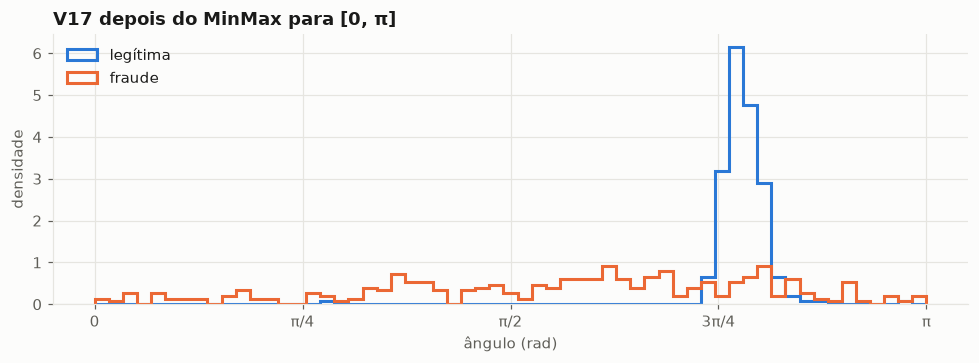

In [32]:
# A feature de maior informação mútua no treino (4.5), e não uma escolhida a partir do que já se sabia
FLATTENING_FEATURE: str = association.index[0]
feature_values = balanced_train_df[FLATTENING_FEATURE]
feature_angles = (feature_values - feature_values.min()) / (feature_values.max() - feature_values.min()) * np.pi
is_balanced_fraud = balanced_train_df[TARGET_COLUMN] == FRAUD_LABEL
legitimate_angles = feature_angles[~is_balanced_fraud]
legitimate_width = legitimate_angles.quantile(0.95) - legitimate_angles.quantile(0.05)

print(f"{FLATTENING_FEATURE} no treino balanceado: mínimo {feature_values.min():.1f} "
      f"(menor fraude {feature_values[is_balanced_fraud].min():.1f}, menor legítima {feature_values[~is_balanced_fraud].min():.1f}), "
      f"máximo {feature_values.max():.1f}")
print(f"90% das legítimas ocupam {legitimate_width:.2f} rad, {legitimate_width / np.pi:.0%} do intervalo [0, π]")

fig, ax = plt.subplots(figsize=(9, 3.4))
bins = np.linspace(0, np.pi, 60)
for label, group_angles in feature_angles.groupby(balanced_train_df[TARGET_COLUMN]):
    ax.hist(group_angles, bins=bins, density=True, histtype="step", linewidth=2,
            color=CLASS_COLORS[label], label=CLASS_NAMES[label])
ax.set(title=f"{FLATTENING_FEATURE} depois do MinMax para [0, π]", xlabel="ângulo (rad)", ylabel="densidade")
ax.set_xticks([0, np.pi / 4, np.pi / 2, 3 * np.pi / 4, np.pi], ["0", "π/4", "π/2", "3π/4", "π"])
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

#### 4.6.2 Standard → MinMax é o mesmo que MinMax sozinho

Exemplo pequeno, com a coluna [1, 2, 3]:
- StandardScaler: [−1,22; 0; 1,22] → MinMaxScaler: **[0; 0,5; 1]**
- MinMaxScaler direto: **[0; 0,5; 1]**

O MinMax só olha a **posição relativa** de cada valor entre o mínimo e o máximo. Qualquer "esticar e deslocar"
aplicado antes (é isso que o StandardScaler e o RobustScaler fazem, coluna a coluna) não muda essas posições.

A consequência é que a escolha do scaler **só importa se houver algo entre ele e o MinMax** que seja sensível à
escala. O PCA é: ele procura as direções de maior variância, e a variância muda com a escala. A seleção por
informação mútua não é: o estimador reescala cada coluna antes de calcular, então esticar e deslocar
uma coluna não muda o resultado. A célula abaixo
verifica tudo isso nos dados reais.

In [33]:
def max_difference(first: np.ndarray, second: np.ndarray) -> float:
    return float(np.abs(first - second).max())


minmax_only = MinMaxScaler().fit_transform(balanced_train_features)
path_outputs = {
    reducer: {
        scaler: build_angle_preprocessor(scaler, reducer, config.N_QUBITS, random_state=config.RANDOM_STATE)
        .fit_transform(balanced_train_features, balanced_train_labels)
        for scaler in ("standard", "robust")
    }
    for reducer in ("pca", "mutual_info")
}

equivalence = pd.DataFrame(
    [
        ("Standard → MinMax  ×  MinMax", max_difference(
            MinMaxScaler().fit_transform(StandardScaler().fit_transform(balanced_train_features)), minmax_only)),
        ("Robust → MinMax  ×  MinMax", max_difference(
            MinMaxScaler().fit_transform(RobustScaler().fit_transform(balanced_train_features)), minmax_only)),
        ("Standard × Robust, com PCA no meio", max_difference(*path_outputs["pca"].values())),
        ("Standard × Robust, com informação mútua no meio", max_difference(*path_outputs["mutual_info"].values())),
    ],
    columns=["comparação", "maior diferença"],
).set_index("comparação")
equivalence["idênticos?"] = equivalence["maior diferença"] < 1e-9
equivalence.style.format({"maior diferença": "{:.4f}"}).set_caption(
    "Maior diferença entre os ângulos produzidos por dois caminhos de pré-processamento (faixa [0, π/2])"
)

,maior diferença,idênticos?
comparação,,
Standard → MinMax × MinMax,0.0000,True
Robust → MinMax × MinMax,0.0000,True
"Standard × Robust, com PCA no meio",1.5509,False
"Standard × Robust, com informação mútua no meio",0.0000,True


#### 4.6.3 Por que padronizar antes do PCA: o caso El Alami et al. (2025)

El Alami et al. subamostraram a base bruta para 492 fraudes + 492 legítimas e aplicaram o PCA às colunas
originais, com `Time` e `Amount` sem escalonamento, para obter 7 componentes (7 qubits). O PCA procura as
direções de **maior variância**. A **escala** (desvio padrão) de `Time` é de 24 mil a 143 mil vezes a das `V`
(4.1), o que em **variância** (desvio ao quadrado) vira uma razão de cerca de 6 × 10⁸ a 2 × 10¹⁰.

A célula aplica o mesmo procedimento (subamostrar 1:1 e fazer o PCA de 7 componentes nas colunas originais, sem
padronizar) às linhas do **treino balanceado**: 284 fraudes + 284 legítimas, em vez das 492 + 492 deles, para não
explorar validação e teste. A última coluna mede quanto de cada componente vem das quatro features de
maior informação mútua no treino (4.5): é a soma dos quadrados das cargas delas, uma fração entre 0 e 1.

In [34]:
# Procedimento de El Alami et al. (subamostrar 1:1 e aplicar o PCA às colunas originais, sem padronizar),
# reproduzido nas MESMAS linhas do treino balanceado, com as colunas brutas
el_alami_sample = train_raw_df.loc[balanced_train_df.index, list(RAW_FEATURE_COLUMNS)]
unscaled_pca = PCA(n_components=7, random_state=config.RANDOM_STATE).fit(el_alami_sample)
loadings = pd.DataFrame(np.abs(unscaled_pca.components_), columns=RAW_FEATURE_COLUMNS)
# As 4 de maior informação mútua no treino (4.5)
FRAUD_SIGNAL_FEATURES: list[str] = list(association.index[:4])
fraction_column = "fração de " + "+".join(FRAUD_SIGNAL_FEATURES)

el_alami_components = pd.DataFrame(
    {
        "variância explicada": unscaled_pca.explained_variance_ratio_,
        "maiores cargas": [
            ", ".join(f"{name} ({value:.2f})" for name, value in loadings.iloc[component].nlargest(3).items())
            for component in range(7)
        ],
        # Cada componente tem norma 1, então a soma das cargas ao quadrado é a fração vinda dessas features
        # .to_numpy(): a soma tem índice 0..6 e a tabela usa "componente 1..7" (alinhar geraria NaN)
        fraction_column: (loadings[FRAUD_SIGNAL_FEATURES] ** 2).sum(axis="columns").to_numpy(),
    },
    index=[f"componente {number}" for number in range(1, 8)],
)
display(
    el_alami_components.style.format({"variância explicada": "{:.2e}", fraction_column: "{:.2f}"})
    .set_caption(f"PCA sem padronização nas {len(el_alami_sample)} linhas do treino balanceado (procedimento de El Alami et al.)")
)

print("PCA do nosso pipeline (padronizado), 5 componentes, variância explicada:")
for scaler in ("standard", "robust"):
    fitted = build_angle_preprocessor(scaler, "pca", config.N_QUBITS, random_state=config.RANDOM_STATE).fit(
        balanced_train_features
    )
    ratios = fitted.named_steps["reducer"].explained_variance_ratio_
    print(f"  {scaler:>8}: {ratios.sum():.1%} (por componente: {np.round(ratios, 3).tolist()})")

,variância explicada,maiores cargas,fração de V17+V14+V10+V12
componente 1,1.00e+00,"Time (1.00), V17 (0.00), V1 (0.00)",0.00
componente 2,2.58e-05,"Amount (1.00), V2 (0.00), V7 (0.00)",0.00
componente 3,8.42e-08,"V3 (0.41), V17 (0.37), V7 (0.34)",0.36
componente 4,1.23e-08,"V1 (0.47), V14 (0.42), V12 (0.33)",0.39
componente 5,7.29e-09,"V8 (0.82), V21 (0.32), V7 (0.28)",0.05
componente 6,4.94e-09,"V17 (0.57), V14 (0.40), V3 (0.35)",0.49
componente 7,1.33e-09,"V1 (0.71), V10 (0.38), V5 (0.31)",0.21


PCA do nosso pipeline (padronizado), 5 componentes, variância explicada:
  standard: 64.8% (por componente: [0.381, 0.101, 0.062, 0.06, 0.043])
    robust: 78.9% (por componente: [0.401, 0.214, 0.07, 0.055, 0.049])


### 4.7 A faixa dos ângulos é a "largura de banda" do kernel

O intervalo do MinMax (o "range") decide quão diferentes os ângulos de duas transações podem ficar:
- **Faixa estreita** (ex.: [0; 0,1]): todos os ângulos quase iguais → todos os estados quase iguais → similaridade
  ≈ 1 para todo par. Como uma foto desfocada: ninguém se distingue.
- **Faixa larga** (ex.: [0, 2π]): pequenas diferenças viram grandes diferenças de estado → similaridade ≈ 0 entre
  linhas diferentes. Cada transação só se parece consigo mesma, e o modelo decora.
- **Entre os dois extremos** existe uma faixa em que o kernel separa as classes melhor, com KTA máximo.

É o mesmo papel do γ no kernel RBF clássico (Shaydulin; Wild, 2022). Os artigos usam [0, 1] (El Alami) ou [0, π]
com justificativas vagas.

O KTA medido em 400 linhas é ruidoso (CC10), então cada configuração é medida em **5 subamostras do treino**: para
cada semente, o undersampler do pipeline balanceia o treino (284 + 284) e 400 dessas linhas entram no kernel. A
tabela mostra média ± desvio. A varredura mede o efeito para três configurações de 5 qubits:
- **ZZ + PCA**
- **ZZ + informação mútua**
- **Z + PCA** (sem emaranhamento: kernel calculável classicamente)

In [35]:
ANGLE_RANGE_WIDTHS: tuple[float, ...] = (0.1, 0.25, 0.5, 1.0, np.pi / 2, np.pi, 2 * np.pi)
MONOTONIC_LIMIT_Z: float = np.pi / 2  # limite do mapa Z (Seção 4.7.1); acima disso, extremos se confundem
SUBSAMPLE_SEEDS: tuple[int, ...] = (config.RANDOM_STATE, 0, 1, 2, 3)
SWEEP_CONFIGURATIONS: dict[str, AngleConfiguration] = {
    "ZZ + PCA": ("zz", "pca"),
    "ZZ + informação mútua": ("zz", "mutual_info"),
    "Z + PCA (sem emaranhamento)": ("z", "pca"),
}
# Rótulos de exibição das colunas devolvidas pelas varreduras do pacote
SWEEP_COLUMN_LABELS: dict[str, str] = {
    "configuration": "configuração",
    "range_width": "largura da faixa (rad)",
    "subsample": "subamostra",
    "padding_value": "constante de preenchimento",
    "mean_similarity": "similaridade média",
    "alignment": "KTA",
}


def train_kernel_subsample(seed: int) -> KernelSubsample:
    """O treino balanceado pelo undersampler do pipeline (com a semente dada), reduzido a KERNEL_SAMPLE_ROWS linhas."""
    features, labels = make_undersampler(seed).fit_resample(X_train, y_train)
    rows = np.random.default_rng(seed).choice(len(features), KERNEL_SAMPLE_ROWS, replace=False)
    return features.to_numpy()[rows], labels.to_numpy()[rows]


def summarize_angle_sweep(sweep: pd.DataFrame) -> pd.DataFrame:
    """Média e desvio do KTA e similaridade média, por largura e configuração."""
    return sweep.groupby(["largura da faixa (rad)", "configuração"], sort=False).agg(
        kta_mean=("KTA", "mean"), kta_std=("KTA", "std"), similarity_mean=("similaridade média", "mean")
    )


kernel_subsamples = {seed: train_kernel_subsample(seed) for seed in SUBSAMPLE_SEEDS}
with CostMeter(trace_python_memory=False) as sweep_meter:
    # Cada combinação (configuração × largura × subamostra) é independente: roda em paralelo nos núcleos
    range_sweep = angle_alignment_sweep(
        kernel_subsamples, SWEEP_CONFIGURATIONS, ANGLE_RANGE_WIDTHS, config.N_QUBITS, config.RANDOM_STATE,
        n_jobs=config.N_JOBS,
    ).rename(columns=SWEEP_COLUMN_LABELS)
sweep_summary = summarize_angle_sweep(range_sweep)
print(f"Varredura: {len(range_sweep)} kernels ({len(SUBSAMPLE_SEEDS)} subamostras) em {sweep_meter.report.wall_seconds:.0f} s")

kta_mean = sweep_summary["kta_mean"].unstack("configuração")
kta_std = sweep_summary["kta_std"].unstack("configuração")
kta_text = kta_mean.map("{:.2f}".format) + " ± " + kta_std.map("{:.2f}".format)
valid_widths = kta_mean.index <= MONOTONIC_LIMIT_Z + 1e-9


def bold_best_valid(column: pd.Series) -> list[str]:
    """Negrito na maior média entre as larguras até π/2 (acima, o mapa Z é patológico)."""
    best = kta_mean.loc[valid_widths, column.name].idxmax()
    return ["font-weight: bold" if width == best else "" for width in column.index]


display(
    kta_text.style.apply(bold_best_valid).set_caption(
        "KTA (média ± desvio em 5 subamostras). Negrito: melhor largura até π/2. "
        "Acima de π/2 (π, 2π) o mapa Z codifica extremos opostos como estados iguais."
    )
)
display(
    sweep_summary["similarity_mean"].unstack("configuração").style.format("{:.2f}").set_caption(
        "Similaridade média entre linhas diferentes (média das 5 subamostras)"
    )
)

Varredura: 105 kernels (5 subamostras) em 34 s


configuração,ZZ + PCA,ZZ + informação mútua,Z + PCA (sem emaranhamento)
largura da faixa (rad),,,
0.100000,0.31 ± 0.02,0.53 ± 0.02,0.38 ± 0.02
0.250000,0.39 ± 0.04,0.64 ± 0.03,0.39 ± 0.02
0.500000,0.44 ± 0.03,0.64 ± 0.03,0.42 ± 0.02
1.000000,0.27 ± 0.06,0.65 ± 0.01,0.45 ± 0.03
1.570796,0.36 ± 0.06,0.66 ± 0.03,0.42 ± 0.05
3.141593,0.29 ± 0.04,0.56 ± 0.11,0.53 ± 0.07
6.283185,0.16 ± 0.02,0.18 ± 0.03,0.31 ± 0.05


configuração,ZZ + PCA,ZZ + informação mútua,Z + PCA (sem emaranhamento)
largura da faixa (rad),,,
0.100000,0.96,0.92,1.00
0.250000,0.77,0.61,0.98
0.500000,0.47,0.45,0.93
1.000000,0.32,0.29,0.71
1.570796,0.20,0.26,0.52
3.141593,0.12,0.23,0.36
6.283185,0.07,0.06,0.20


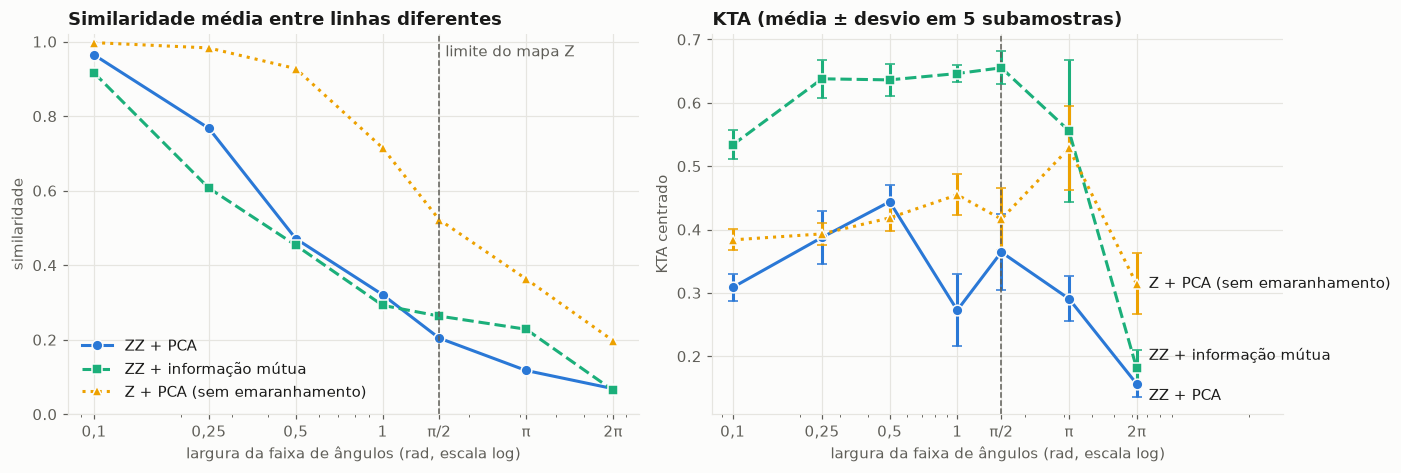

In [36]:
SWEEP_STYLES: dict[str, dict[str, str]] = {
    "ZZ + PCA": {"color": "#2a78d6", "marker": "o", "linestyle": "-"},
    "ZZ + informação mútua": {"color": "#1baf7a", "marker": "s", "linestyle": "--"},
    "Z + PCA (sem emaranhamento)": {"color": "#eda100", "marker": "^", "linestyle": ":"},
}

# Deslocamentos dos rótulos diretos: as duas curvas ZZ terminam com KTA quase igual em 2π
LABEL_OFFSETS: dict[str, tuple[int, int]] = {
    "ZZ + PCA": (8, -8),
    "ZZ + informação mútua": (8, 8),
    "Z + PCA (sem emaranhamento)": (8, 0),
}

fig, (similarity_ax, alignment_ax) = plt.subplots(1, 2, figsize=(13, 4.4))
for configuration, style in SWEEP_STYLES.items():
    rows = sweep_summary.xs(configuration, level="configuração")
    widths = rows.index.to_numpy()
    similarity_ax.plot(widths, rows["similarity_mean"], markersize=7, markeredgecolor="#fcfcfb",
                       label=configuration, **style)
    alignment_ax.errorbar(widths, rows["kta_mean"], yerr=rows["kta_std"], markersize=7, markeredgecolor="#fcfcfb",
                          capsize=3, label=configuration, **style)
    # Rótulo direto no último ponto do painel de KTA: a série não depende só da cor
    alignment_ax.annotate(configuration, xy=(widths[-1], rows["kta_mean"].iloc[-1]), xytext=LABEL_OFFSETS[configuration],
                          textcoords="offset points", va="center", color="#1a1a19")

for ax in (similarity_ax, alignment_ax):
    ax.set_xscale("log")
    ax.set_xticks(ANGLE_RANGE_WIDTHS, ["0,1", "0,25", "0,5", "1", "π/2", "π", "2π"])
    ax.set_xlabel("largura da faixa de ângulos (rad, escala log)")
    ax.axvline(MONOTONIC_LIMIT_Z, color="#5f5e58", linewidth=1, linestyle="--")
# O rótulo da linha vertical fica no painel da esquerda, onde não há curva por perto
similarity_ax.annotate("limite do mapa Z", xy=(MONOTONIC_LIMIT_Z, 1.0), xytext=(4, -2),
                       textcoords="offset points", va="top", color="#5f5e58")
similarity_ax.set(title="Similaridade média entre linhas diferentes", ylabel="similaridade", ylim=(0, 1.02))
similarity_ax.legend(loc="lower left")
alignment_ax.set(title="KTA (média ± desvio em 5 subamostras)", ylabel="KTA centrado")
alignment_ax.set_xlim(right=2 * np.pi * 4.5)
plt.tight_layout()
plt.show()

A média esconde o formato da distribuição. Os histogramas mostram **todas** as similaridades entre pares
de linhas diferentes (ZZ + PCA, primeira subamostra) em três larguras: com a faixa estreita elas se amontoam perto
de 1; com a larga, perto de 0. É a concentração do kernel vista diretamente.

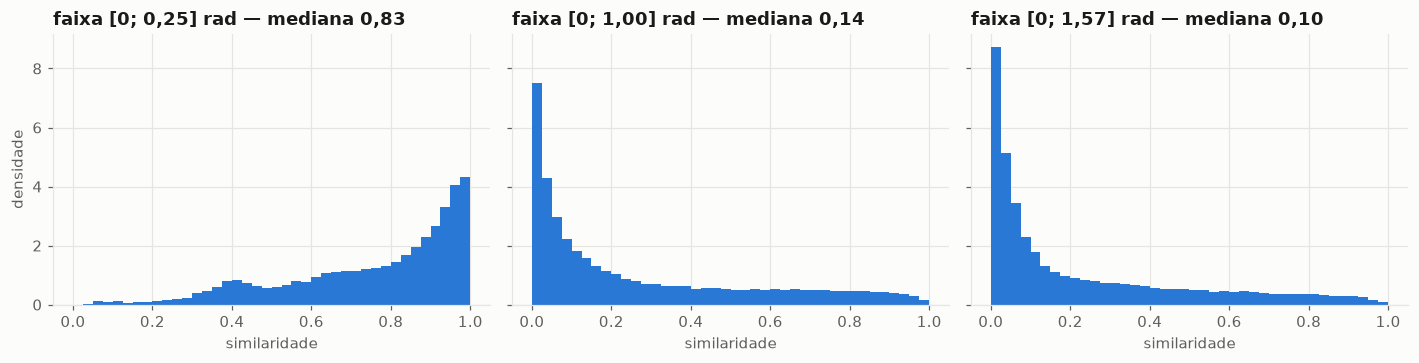

In [37]:
CONCENTRATION_WIDTHS: tuple[float, ...] = (0.25, 1.0, np.pi / 2)
concentration_features, concentration_labels = kernel_subsamples[config.RANDOM_STATE]
zz_map = build_angle_feature_map("zz", config.N_QUBITS)
fig, axes = plt.subplots(1, len(CONCENTRATION_WIDTHS), figsize=(13, 3.4), sharey=True)
for ax, width in zip(axes, CONCENTRATION_WIDTHS):
    angles = build_angle_preprocessor("standard", "pca", config.N_QUBITS, (0.0, width), config.RANDOM_STATE).fit_transform(
        concentration_features, concentration_labels
    )
    similarities = off_diagonal_values(angle_kernel_matrix(zz_map, angles))
    ax.hist(similarities, bins=np.linspace(0, 1, 41), color=NEUTRAL_SERIES_COLOR, density=True)
    ax.set(title=f"faixa [0; {width:.2f}] rad — mediana {np.median(similarities):.2f}".replace(".", ","),
           xlabel="similaridade")
axes[0].set_ylabel("densidade")
plt.tight_layout()
plt.show()

O "melhor ponto" de uma curva ruidosa pode ser acaso. A tabela conta, para cada configuração, em quantas das 5
subamostras cada largura válida (até π/2) foi a melhor, e lista as larguras cujo KTA médio fica a menos de 1 desvio
do máximo. São essas que o grid (`config.ANGLE_RANGE_WIDTH_GRID`) precisa conter, e não só a melhor.

In [38]:
valid_sweep = range_sweep[range_sweep["largura da faixa (rad)"] <= MONOTONIC_LIMIT_Z + 1e-9]
best_per_subsample = valid_sweep.loc[valid_sweep.groupby(["configuração", "subamostra"], sort=False)["KTA"].idxmax()]
best_width_counts = pd.crosstab(best_per_subsample["configuração"], best_per_subsample["largura da faixa (rad)"])
best_width_counts = best_width_counts.reindex(columns=[w for w in ANGLE_RANGE_WIDTHS if w <= MONOTONIC_LIMIT_Z + 1e-9],
                                              fill_value=0)
best_width_counts.columns = ["0,1", "0,25", "0,5", "1", "π/2"]


def widths_near_the_best(configuration: str) -> list[float]:
    """Larguras válidas cujo KTA médio fica a menos de 1 desvio (o da melhor) do máximo."""
    rows = sweep_summary.xs(configuration, level="configuração")
    rows = rows[rows.index <= MONOTONIC_LIMIT_Z + 1e-9]
    best = rows["kta_mean"].idxmax()
    return rows.index[rows["kta_mean"] >= rows.loc[best, "kta_mean"] - rows.loc[best, "kta_std"]].tolist()


near_best = {name: widths_near_the_best(name) for name in best_width_counts.index}
best_width_counts["larguras a < 1 desvio do máximo"] = [
    ", ".join(f"{width:.2f}" for width in near_best[name]) for name in best_width_counts.index
]
best_width_counts["todas no grid?"] = [
    all(any(np.isclose(width, option) for option in config.ANGLE_RANGE_WIDTH_GRID) for width in near_best[name])
    for name in best_width_counts.index
]
best_width_counts.loc[list(SWEEP_CONFIGURATIONS)].style.set_caption(
    "Em quantas das 5 subamostras cada largura válida foi a melhor, e quais ficam a menos de 1 desvio do máximo"
)

,"0,1","0,25","0,5",1,π/2,larguras a < 1 desvio do máximo,todas no grid?
configuração,,,,,,,
ZZ + PCA,0,0,5,0,0,0.50,True
ZZ + informação mútua,0,1,0,2,2,"0.25, 0.50, 1.00, 1.57",True
Z + PCA (sem emaranhamento),0,0,0,5,0,1.00,True


#### 4.7.1 Armadilha: ângulos são periódicos, e os mapas do Qiskit dobram o ângulo

Uma rotação de 2π é uma volta completa: o qubit volta ao mesmo estado. Isso cria riscos que os artigos não
discutem:

1. **Valores fora da faixa do treino.** Uma transação da validação ou do teste mais extrema que todas as do treino
   ultrapassaria o limite da faixa, "daria a volta" e ficaria parecida com o extremo **oposto**. O
   `clip=True` do MinMax (a etapa `angle_scaler` do pipeline) a mantém na borda.
2. **O fator 2 dos feature maps do Qiskit.** O `z_feature_map` e o `zz_feature_map` aplicam a rotação P(α·x) com
   **α = 2** por padrão, então o período em x cai de 2π para **π**. No **mapa Z**, na faixa [0, π] (a mais usada na
   literatura), as duas pontas viram o **mesmo estado**: a fraude mais extrema fica codificada igual ao valor máximo.
   Até π/2, no mapa Z, "mais distante" sempre significa "menos parecido".
3. **No ZZ, a monotonicidade acaba antes.** O termo de pares, (π − xᵢ)(π − xⱼ), também multiplicado por 2, varia
   bem mais rápido que os termos de 1 qubit. A similaridade cai perto de zero e **volta a subir** antes mesmo de π/2.
   Não é a patologia do Z (estados idênticos), mas "mais distante" deixa de significar "menos parecido".

O gráfico mostra a similaridade entre um ponto e o mesmo ponto com uma feature deslocada de Δ: 1 qubit no mapa Z,
e 5 qubits no ZZ (as outras features fixas em 0,5 rad).

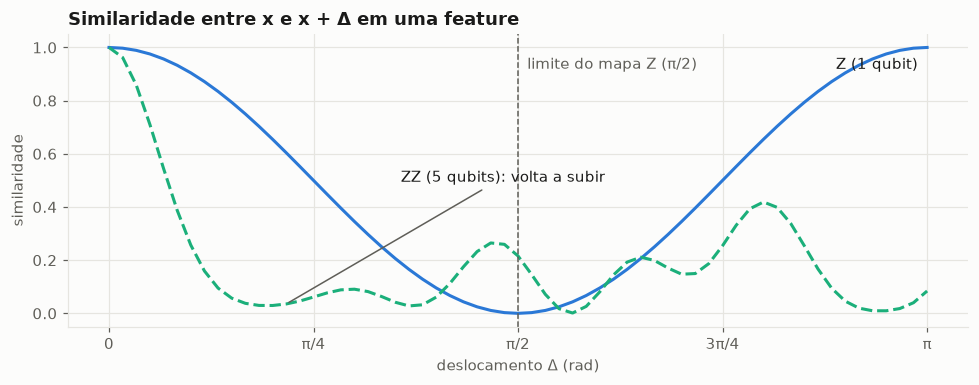

ZZ: a similaridade atinge o primeiro mínimo em Δ = 0.63 rad e depois volta a subir
 Z, 5 qubits, faixa [0, π]: extremos opostos (tudo 0 × tudo π) = 1.00; média entre pares quaisquer = 0.36
ZZ, 5 qubits, faixa [0, π]: extremos opostos (tudo 0 × tudo π) = 0.44; média entre pares quaisquer = 0.17


In [39]:
distances = np.linspace(0, np.pi, 61)
single_qubit_z = build_angle_feature_map("z", n_qubits=1)
z_similarity = angle_kernel_matrix(single_qubit_z, [[0.0]], distances.reshape(-1, 1))[0]

zz_reference = np.full((1, config.N_QUBITS), 0.5)
zz_shifted = np.repeat(zz_reference, len(distances), axis=0)
zz_shifted[:, -1] = 0.5 + distances
zz_similarity = angle_kernel_matrix(build_angle_feature_map("zz", config.N_QUBITS), zz_reference, zz_shifted)[0]

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(distances, z_similarity, color=NEUTRAL_SERIES_COLOR)
ax.plot(distances, zz_similarity, color="#1baf7a", linestyle="--")
ax.annotate("Z (1 qubit)", xy=(np.pi, 1.0), xytext=(-6, -14), textcoords="offset points", ha="right", color="#1a1a19")
first_rise = int(np.argmax(np.diff(zz_similarity) > 0)) + 1
ax.annotate("ZZ (5 qubits): volta a subir", xy=(distances[first_rise], zz_similarity[first_rise]),
            xytext=(75, 80), textcoords="offset points", color="#1a1a19",
            arrowprops={"arrowstyle": "-", "color": "#5f5e58", "linewidth": 1})
ax.axvline(np.pi / 2, color="#5f5e58", linewidth=1, linestyle="--")
ax.annotate("limite do mapa Z (π/2)", xy=(np.pi / 2, 0.92), xytext=(6, 0), textcoords="offset points", color="#5f5e58")
ax.set(title="Similaridade entre x e x + Δ em uma feature", xlabel="deslocamento Δ (rad)", ylabel="similaridade")
ax.set_xticks([0, np.pi / 4, np.pi / 2, 3 * np.pi / 4, np.pi], ["0", "π/4", "π/2", "3π/4", "π"])
plt.tight_layout()
plt.show()

print(f"ZZ: a similaridade atinge o primeiro mínimo em Δ = {distances[first_rise - 1]:.2f} rad e depois volta a subir")
all_zeros, all_pi = np.zeros((1, config.N_QUBITS)), np.full((1, config.N_QUBITS), np.pi)
for map_name in ("z", "zz"):
    extremes_similarity = angle_kernel_matrix(build_angle_feature_map(map_name, config.N_QUBITS), all_zeros, all_pi)[0, 0]
    typical_similarity = range_sweep.query(
        "`largura da faixa (rad)` == @np.pi and configuração.str.startswith(@map_name.upper() + ' ')"
    )["similaridade média"].mean()
    print(f"{map_name.upper():>2}, 5 qubits, faixa [0, π]: extremos opostos (tudo 0 × tudo π) = {extremes_similarity:.2f}; "
          f"média entre pares quaisquer = {typical_similarity:.2f}")

### 4.8 Ângulo × amplitude

A codificação de amplitude (Variação B do TCC) usa as 31 features, mais uma constante, como as 32 amplitudes de
um estado de 5 qubits. Duas propriedades dela pesam na interpretação:
- **O kernel é calculável classicamente.** A similaridade entre dois estados é cos²(ângulo entre os vetores), uma
  conta clássica simples. O teste `test_amplitude_kernel_matches_qiskit_simulation` mostra que a simulação do Qiskit
  dá exatamente esse valor.
- **A normalização descarta a norma do vetor.** Um estado quântico precisa ter norma 1, então x e 2x viram o
  **mesmo** estado. Só que a norma é sinal de fraude: fraudes ficam mais longe do centro dos dados. Completar as
  posições vazias com uma **constante** (e não com zero) preserva essa informação, porque o ângulo entre o vetor e
  o eixo da constante passa a depender da norma. O tamanho da constante vira um hiperparâmetro.

In [40]:
standardized_norms = np.linalg.norm(StandardScaler().fit_transform(balanced_train_features), axis=1)
print("Norma do vetor padronizado (mediana): "
      f"legítimas {np.median(standardized_norms[balanced_train_labels == LEGITIMATE_LABEL]):.2f}, "
      f"fraudes {np.median(standardized_norms[balanced_train_labels == FRAUD_LABEL]):.2f}")

# Até 10, para o melhor valor não ficar na borda da varredura (com só 0, 1 e 3, ficava)
AMPLITUDE_PADDING_VALUES: tuple[float, ...] = (0.0, 1.0, 3.0, 5.0, 10.0)
AMPLITUDE_SCALERS: tuple[ScalerName, ...] = ("standard", "robust")


def summarize_amplitude_sweep(sweep: pd.DataFrame) -> pd.DataFrame:
    """Média da similaridade e média ± desvio do KTA, por scaler e constante."""
    return sweep.groupby(["scaler", "constante de preenchimento"]).agg(
        similaridade_media=("similaridade média", "mean"), KTA_media=("KTA", "mean"), KTA_desvio=("KTA", "std")
    )


amplitude_sweep = amplitude_alignment_sweep(
    kernel_subsamples, AMPLITUDE_SCALERS, AMPLITUDE_PADDING_VALUES, config.N_QUBITS
).rename(columns=SWEEP_COLUMN_LABELS)
amplitude_comparison = summarize_amplitude_sweep(amplitude_sweep)
amplitude_comparison.style.format("{:.2f}").set_caption("Amplitude: média de 5 subamostras")

Norma do vetor padronizado (mediana): legítimas 3.80, fraudes 4.88


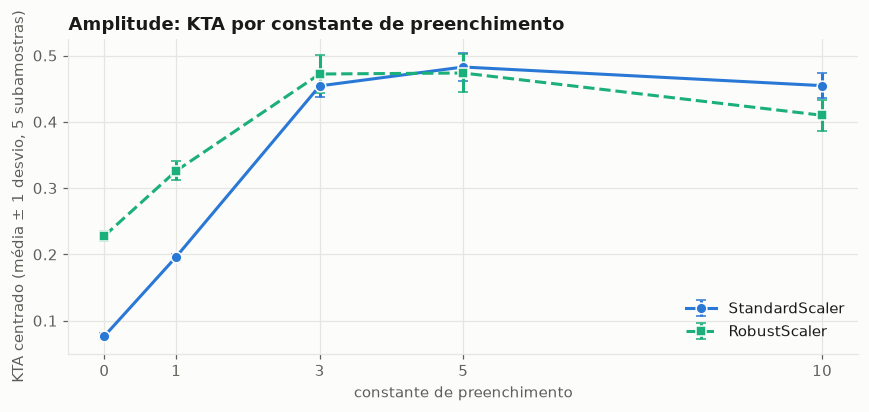

In [41]:
AMPLITUDE_SCALER_STYLES: dict[str, dict[str, str]] = {
    "standard": {"color": "#2a78d6", "marker": "o", "linestyle": "-", "label": "StandardScaler"},
    "robust": {"color": "#1baf7a", "marker": "s", "linestyle": "--", "label": "RobustScaler"},
}

fig, ax = plt.subplots(figsize=(8, 3.8))
for scaler, style in AMPLITUDE_SCALER_STYLES.items():
    rows = amplitude_comparison.xs(scaler, level="scaler")
    ax.errorbar(rows.index.to_numpy(), rows["KTA_media"], yerr=rows["KTA_desvio"], markersize=7,
                markeredgecolor="#fcfcfb", capsize=3, **style)
ax.set_xticks(list(AMPLITUDE_PADDING_VALUES))
ax.set(title="Amplitude: KTA por constante de preenchimento",
       xlabel="constante de preenchimento", ylabel="KTA centrado (média ± 1 desvio, 5 subamostras)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### 4.9 Seleção de features: PCA × informação mútua

Com 5 qubits na codificação de ângulo, as 31 features precisam virar 5. As duas estratégias fazem apostas
diferentes:
- **PCA:** combina todas as features em 5 eixos de máxima **variância**. Não sabe o que é fraude. Preserva o
  máximo de informação geral, que pode ou não ser a informação útil.
- **Informação mútua:** mantém as 5 features que individualmente mais dizem sobre o **rótulo**. Mas avalia cada
  uma isoladamente: se duas carregam a mesma informação, as duas podem ser escolhidas e um qubit é desperdiçado.

**Cuidado ao ler o KTA da informação mútua na Seção 4.7:** ela escolheu as features olhando o rótulo *destas
mesmas linhas*, então o seu KTA aqui é otimista. A comparação justa só acontece na validação cruzada, em que a
seleção é refeita em cada fold sem ver as linhas avaliadas.

A segunda célula repete a seleção com as 5 sementes do sorteio, para ver quais features são escolhidas sempre e
quais dependem do acaso.

In [42]:
mutual_info_path = build_angle_preprocessor(
    "standard", "mutual_info", config.N_QUBITS, random_state=config.RANDOM_STATE
).fit(balanced_train_features, balanced_train_labels)
selected_mask = mutual_info_path.named_steps["reducer"].get_support()
selected_features = [name for name, keep in zip(MODEL_FEATURE_COLUMNS, selected_mask) if keep]
print(f"Informação mútua escolheu: {selected_features}")


def mean_absolute_correlation(frame: pd.DataFrame) -> float:
    """Média do |r| entre pares de colunas distintas."""
    correlation = frame.corr().to_numpy()
    return float(np.abs(correlation[np.triu_indices_from(correlation, k=1)]).mean())


is_fraud = balanced_train_df[TARGET_COLUMN] == FRAUD_LABEL
pca_path = build_angle_preprocessor("standard", "pca", config.N_QUBITS, random_state=config.RANDOM_STATE).fit(
    balanced_train_features
)
fraud_components = pd.DataFrame(pca_path[:-1].transform(balanced_train_features[is_fraud.to_numpy()]))
redundancy = pd.Series(
    {
        "5 escolhidas pela MI, nas fraudes": mean_absolute_correlation(balanced_train_df.loc[is_fraud, selected_features]),
        "5 escolhidas pela MI, nas legítimas": mean_absolute_correlation(balanced_train_df.loc[~is_fraud, selected_features]),
        "todas as 28 V, nas fraudes": mean_absolute_correlation(balanced_train_df.loc[is_fraud, list(PCA_FEATURE_COLUMNS)]),
        "5 componentes do PCA, nas fraudes": mean_absolute_correlation(fraud_components),
    },
    name="correlação absoluta média",
)
display(redundancy.to_frame().style.format("{:.2f}").set_caption("Redundância entre as features que ocupariam os 5 qubits"))
balanced_train_df.loc[is_fraud, selected_features].corr().style.format("{:.2f}").set_caption(
    "Correlação entre as 5 features escolhidas, nas fraudes do treino"
)

Informação mútua escolheu: ['V4', 'V10', 'V12', 'V14', 'V17']


,correlação absoluta média
"5 escolhidas pela MI, nas fraudes",0.75
"5 escolhidas pela MI, nas legítimas",0.21
"todas as 28 V, nas fraudes",0.31
"5 componentes do PCA, nas fraudes",0.06


,V4,V10,V12,V14,V17
V4,1.00,-0.73,-0.79,-0.68,-0.61
V10,-0.73,1.00,0.85,0.69,0.82
V12,-0.79,0.85,1.00,0.84,0.84
V14,-0.68,0.69,0.84,1.00,0.63
V17,-0.61,0.82,0.84,0.63,1.00


In [43]:
selections_by_seed: dict[int, list[str]] = {}
for seed in SUBSAMPLE_SEEDS:
    seed_features, seed_labels = make_undersampler(seed).fit_resample(X_train, y_train)
    reducer = build_angle_preprocessor(
        "standard", "mutual_info", config.N_QUBITS, random_state=config.RANDOM_STATE
    ).fit(seed_features.to_numpy(), seed_labels.to_numpy()).named_steps["reducer"]
    selections_by_seed[seed] = [name for name, keep in zip(MODEL_FEATURE_COLUMNS, reducer.get_support()) if keep]

selection_counts = Counter(feature for selection in selections_by_seed.values() for feature in selection)
selection_table = pd.DataFrame(
    {f"subamostra {seed}": {feature: "✓" if feature in selection else "" for feature in selection_counts}
     for seed, selection in selections_by_seed.items()}
)
selection_table["vezes escolhida (de 5)"] = pd.Series(selection_counts)
selection_table = selection_table.sort_values("vezes escolhida (de 5)", ascending=False)
# A redundância de cada escolha: |r| médio entre as 5 features, nas fraudes do treino
train_fraud_features = X_train[y_train == FRAUD_LABEL]
selection_table.loc["|r| médio entre as 5, nas fraudes"] = [
    *(f"{mean_absolute_correlation(train_fraud_features[selection]):.2f}" for selection in selections_by_seed.values()),
    "",
]
selection_table.style.set_caption(
    "As 5 features escolhidas pela informação mútua no treino balanceado, por subamostra "
    "(SUBSAMPLE_SEEDS; não são as sementes de robustez da Seção 9)"
)

,subamostra 42,subamostra 0,subamostra 1,subamostra 2,subamostra 3,vezes escolhida (de 5)
V10,✓,✓,✓,✓,✓,5
V12,✓,✓,✓,✓,✓,5
V17,✓,✓,✓,✓,✓,5
V14,✓,✓,✓,✓,✓,5
V4,✓,,✓,✓,✓,4
V3,,✓,,,,1
"|r| médio entre as 5, nas fraudes",0.75,0.72,0.75,0.75,0.75,


### 4.10 Undersampling: só no treino, e só dentro do pipeline

O `RandomUnderSampler` descarta legítimas ao acaso até igualar as fraudes (razão 1:1). Ele entra como **primeira
etapa do pipeline** (`imblearn.pipeline.Pipeline`), o que garante três coisas:
- **Só age no `fit`.** Na predição ele é pulado, então validação e teste são sempre avaliados com a proporção real.
- **O sorteio usa apenas linhas de treino.**
- **A semente é um parâmetro.** A análise de robustez (Seção 9) repete tudo com as 5 sementes de `config`.

A célula prova as duas primeiras garantias com um pipeline mínimo. O modelo dele é um
`DummyClassifier(strategy="prior")`, que não olha as features: ele só aprende a proporção de classes que chega até
ele. Isso torna visível **o que o undersampling ensina a qualquer modelo** sobre a frequência da fraude. O teste
`test_undersampler_balances_training_and_skips_prediction` verifica o mesmo no pacote.

In [44]:
undersampled_features, undersampled_labels = make_undersampler(config.RANDOM_STATE).fit_resample(X_train, y_train)

prior_probe = ImbPipeline(
    [
        ("undersampler", make_undersampler(config.RANDOM_STATE)),
        ("scaler", StandardScaler()),
        ("model", DummyClassifier(strategy="prior")),
    ]
).fit(X_train, y_train)
validation_fraud_scores = prior_probe.predict_proba(X_validation)[:, 1]

assert undersampled_labels.value_counts().to_dict() == {LEGITIMATE_LABEL: train_frauds, FRAUD_LABEL: train_frauds}
assert undersampled_features.index.isin(train_df.index).all(), "o sorteio só pode usar linhas de treino"
assert len(validation_fraud_scores) == len(X_validation), "na predição, nenhuma linha pode ser descartada"

learned_prior = prior_probe.named_steps["model"].class_prior_[1]
print(f"Treino antes do undersampling: {train_legitimate:,} legítimas e {train_frauds} fraudes")
print(f"Treino depois (o que o modelo vê): {len(undersampled_labels)} linhas, {undersampled_labels.mean():.0%} fraudes")
print(f"Validação avaliada: {len(validation_fraud_scores):,} linhas ({y_validation.mean():.4%} fraudes)")
print(f"P(fraude) aprendida pelo modelo: {learned_prior:.2f}  |  proporção real na validação: {y_validation.mean():.4f} "
      f"({learned_prior / y_validation.mean():.0f}× menor)")

# A correção de Dal Pozzolo et al. (2015), aplicada ao 0,50 aprendido, precisa devolver a proporção do treino
corrected_prior = float(undersampling_corrected_probability(learned_prior, legitimate_keep_probability))
assert np.isclose(corrected_prior, y_train.mean())
print(f"0,50 corrigido pela fórmula de Dal Pozzolo: {corrected_prior:.5f} = proporção de fraudes no treino ({y_train.mean():.5f})")

Treino antes do undersampling: 169,951 legítimas e 284 fraudes
Treino depois (o que o modelo vê): 568 linhas, 50% fraudes
Validação avaliada: 56,745 linhas (0.1657% fraudes)
P(fraude) aprendida pelo modelo: 0.50  |  proporção real na validação: 0.0017 (302× menor)
0,50 corrigido pela fórmula de Dal Pozzolo: 0.00167 = proporção de fraudes no treino (0.00167)


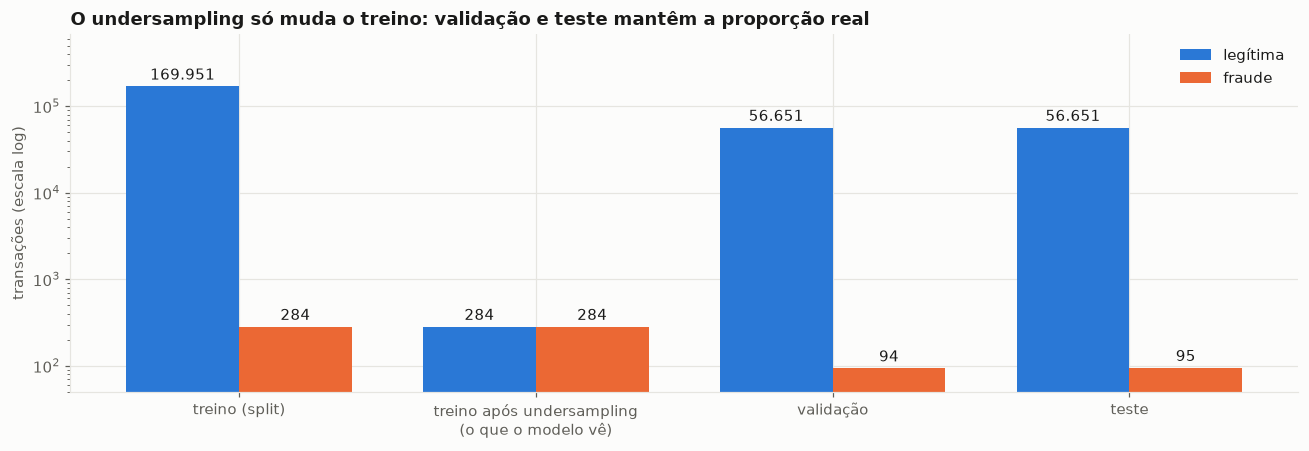

In [45]:
composition = pd.DataFrame(
    {
        "treino (split)": y_train.value_counts(),
        "treino após undersampling\n(o que o modelo vê)": undersampled_labels.value_counts(),
        "validação": y_validation.value_counts(),
        "teste": test_df[TARGET_COLUMN].value_counts(),
    }
).loc[[LEGITIMATE_LABEL, FRAUD_LABEL]]

fig, ax = plt.subplots(figsize=(12, 4.2))
positions = np.arange(composition.shape[1])
bar_width = 0.38
for offset, label in zip((-bar_width / 2, bar_width / 2), composition.index):
    bars = ax.bar(positions + offset, composition.loc[label], width=bar_width, color=CLASS_COLORS[label], label=CLASS_NAMES[label])
    ax.bar_label(bars, labels=[brazilian_integer(int(n)) for n in composition.loc[label]], padding=2)
ax.set_yscale("log")
ax.set_xticks(positions, composition.columns)
ax.set(title="O undersampling só muda o treino: validação e teste mantêm a proporção real",
       ylabel="transações (escala log)", ylim=(50, composition.to_numpy().max() * 4))
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

### 4.11 Leitura dos resultados e decisões para o grid

Todos os números abaixo vêm do **treino** (o treino balanceado ou as 5 subamostras dele).

**1. O MinMax espreme as legítimas, mas isso não é necessariamente ruim.** Na `V17`, a feature de maior
informação mútua no treino, 90% das legítimas ocupam 0,21 rad, só 7% do intervalo [0, π]. Para separar fraude de legítima, as legítimas não precisam ser
distinguíveis entre si; o problema são as fraudes *parecidas* com legítimas, que caem justamente na fatia de menor
resolução. Quanta resolução essa fatia recebe é o que a largura da faixa controla (item 4).

**2. Standard → MinMax é idêntico a MinMax sozinho, e Robust → MinMax também** (diferença 0,0000).
- Com **informação mútua** no meio, Standard e Robust continuam idênticos: o estimador reescala cada coluna, e o
  MinMax final desfaz o scaler.
- Com **PCA** no meio, divergem: a maior diferença é 1,55 rad, quase a largura inteira da faixa padrão
  (π/2 ≈ 1,57). A causa está na 4.6.0: nas `V` mais informativas, média e mediana ficam a cerca de meio desvio uma
  da outra no treino balanceado, e os dois scalers centralizam em pontos diferentes.

**3. O PCA sem padronização gasta 2 dos 7 qubits com escala, não com informação.** O procedimento de El Alami et
al. (2025), aplicado às 568 linhas do treino balanceado:
- o 1º componente é `Time` (carga 1,00, praticamente 100% da variância) e o 2º é `Amount`;
- do 3º ao 7º são **misturas que incluem as features de fraude**: `V17`, `V14`, `V3` e `V10` aparecem entre as
  maiores cargas, e a fração vinda das 4 de maior informação mútua (`V17`, `V14`, `V10` e `V12`) é de 0,36;
  0,39; 0,05; 0,49 e 0,21.
- Como o MinMax reescala cada componente depois, a variância minúscula do 3º ao 7º não os apaga: o prejuízo são os
  dois qubits ocupados por "quando" e "quanto". Com padronização, 5 componentes explicam 64,8% (Standard) ou 78,9%
  (Robust) da variância; os dois números **não são comparáveis**, porque cada scaler muda a variância total, e
  explicar mais variância não significa separar melhor as classes.

**4. A faixa dos ângulos funciona como largura de banda, mas o KTA é ruidoso.** Médias de 5 subamostras do treino:
- A similaridade média cai monotonicamente com a largura (ZZ + PCA: 0,96 em 0,1 rad até 0,07 em 2π), e os
  histogramas mostram a concentração se deslocando de perto de 1 para perto de 0 (medianas de 0,83; 0,14 e 0,10).
- Maior KTA médio entre as larguras válidas (≤ π/2):

  | Configuração | Largura de maior média | KTA | KTA em [0, π] |
  |---|---|---|---|
  | ZZ + PCA | 0,5 rad | 0,44 ± 0,03 | 0,29 ± 0,04 |
  | ZZ + informação mútua | π/2 | 0,66 ± 0,03 (otimista, ver 4.9) | 0,56 ± 0,11 |
  | Z + PCA | 1 rad | 0,45 ± 0,03 | 0,53 ± 0,07 (patológico) |

- **A "melhor largura" não deve ser lida como um resultado.** Nestas 5 subamostras, ZZ + PCA teve a melhor largura
  em 0,5 rad e Z + PCA em 1 rad, todas as vezes; no ZZ + informação mútua ela muda de uma para outra (0,25 em 1;
  1 em 2; π/2 em 2), porque a curva é plana entre 0,25 e π/2 (0,64 a 0,66).
- **Cinco subamostras são pouco, e não são independentes.** Cada uma usa 400 das 568 linhas do treino balanceado,
  e as 284 fraudes são sempre as mesmas: duas subamostras compartilham cerca de 70% das fraudes. O desvio entre
  elas subestima a incerteza real.
- **O que a varredura sustenta é só a região.** Em todas as configurações, as larguras a menos de 1 desvio do
  máximo estão em `config.ANGLE_RANGE_WIDTH_GRID` (0,25; 0,5; 1; π/2), e 0,1 rad não foi a melhor em nenhuma das 15
  combinações. É um critério fraco por construção: 4 das 5 larguras válidas estão no grid, então ele só falharia
  se a melhor fosse 0,1 rad.
- O desvio entre subamostras chega a 0,11 (ZZ + informação mútua em π): um número isolado de KTA não decide nada.

**5. Mapa Z × ZZ: sem diferença conclusiva.** Nas faixas válidas, o Z + PCA (0,45 ± 0,03) e o ZZ + PCA
(0,44 ± 0,03) empatam. O 0,53 do Z em [0, π] vem da configuração patológica (4.7.1) e não conta. A pergunta "o
emaranhamento ajuda?" fica em aberto para a validação cruzada.

**6. A periodicidade tem dois limites diferentes.** No mapa Z, extremos opostos em [0, π] viram o mesmo estado
(similaridade 1,00), e até π/2 a similaridade cai monotonicamente. No ZZ, o termo de pares faz a similaridade atingir
um primeiro mínimo em Δ ≈ 0,63 rad e voltar a subir: a monotonicidade acaba antes de π/2.

**7. Na amplitude, a constante de preenchimento importa, e age como largura de banda.** KTA com StandardScaler:
0,08 (zeros) → 0,20 (constante 1) → 0,45 (3) → **0,48** (5) → 0,45 (10): sobe até 5 e cai em 10. Com RobustScaler:
0,23 → 0,33 → 0,47 → 0,47 → 0,41: as constantes 3 e 5 empatam, e 10 é pior. Os desvios entre subamostras são de no
máximo 0,03. A norma é informativa (mediana de 3,80 nas legítimas e 4,88 nas fraudes), e completar com zero a
descarta.

**8. As features da informação mútua são justamente o bloco que se move junto nas fraudes.**
- No treino balanceado ela escolheu `V4`, `V10`, `V12`, `V14` e `V17`. A correlação absoluta média entre elas é
  0,75 nas fraudes, contra 0,21 nas legítimas, 0,31 entre todas as 28 `V` nas fraudes e 0,06 entre os 5 componentes
  do PCA. A informação mútua escolhe features relevantes, mas redundantes entre si; o PCA, por construção, não
  repete informação.
- Nas 5 subamostras, `V10`, `V12`, `V14` e `V17` são escolhidas sempre; a quinta varia (`V4` em 4, `V3` em 1), e a
  redundância fica entre 0,72 e 0,75.
- O ranking muda entre o treino inteiro e o treino balanceado, em que a proporção de classes e o tamanho da amostra
  mudam juntos: no treino inteiro (4.5) a quinta colocada é a `V11`; no balanceado, ela não é escolhida nenhuma vez.
  Mais um motivo para a seleção morar dentro do pipeline.

**9. O undersampling ensina ao modelo que metade das transações é fraude.** No `fit`, o pipeline mínimo recebeu 568
linhas (50% de fraudes), sorteadas só do treino; no `predict`, avaliou as 56.745 linhas da validação, sem descartar
nenhuma. O `DummyClassifier` aprendeu P(fraude) = 0,50, 302 vezes a proporção real da validação. A correção de Dal
Pozzolo et al. (2015), aplicada a esse 0,50, devolve 0,00167, exatamente a proporção do treino antes do
undersampling: a fórmula (`undersampling_corrected_probability`, com teste) é consistente com o pipeline. Todo
modelo treinado no treino balanceado herda esse viés e superestima a probabilidade de fraude; a correção é
crescente, então a **ordem** das transações (e, com ela, ROC-AUC e PR-AUC) não muda, mas o limiar 0,5 deixa de ser
a escolha natural. Por isso o limiar é escolhido na validação, com a proporção real (Seção 7).

**Alcance, e o que esta seção não consegue garantir.**
- O KTA é só um indicador para delimitar a região do grid: a escolha entre as opções é da validação cruzada
  (Seção 6).
- **O grid não nasceu aqui.** Uma versão anterior deste notebook fez estas análises antes do split, com todas as
  473 fraudes (CC7 em `methodological_issues.md`), e as opções do grid foram desenhadas primeiro com aqueles
  números. As 284 fraudes do treino são um subconjunto daquelas. Refeitas só no treino, as análises sustentam as
  mesmas opções, mas isso não é uma replicação independente: é a garantia, mais estreita, de que cada opção pode
  ser justificada **sem** os rótulos de validação e teste.
- O mesmo vale para o `log1p(Amount)` e para a hora em seno/cosseno, que vieram do trabalho anterior (4.4).

**Opções que seguem para o grid (Seção 6):**

| Dimensão | Opções | Motivo |
|---|---|---|
| Redutor (ângulo) | PCA, informação mútua | Apostas diferentes (variância × rótulo); a informação mútua fica acima no KTA, mas com viés otimista |
| Scaler | Standard, Robust **só no caminho com PCA e na amplitude** | Com a informação mútua, os dois são idênticos (item 2) |
| Faixa dos ângulos | 0,25; 0,5; 1; π/2 | Contém todas as larguras a menos de 1 desvio do máximo; π e 2π ficam de fora (patológicos no Z, piores no ZZ) |
| Feature map | Z, ZZ, com 1 ou 2 repetições | Sem diferença conclusiva no KTA (item 5): a validação cruzada decide |
| Constante da amplitude | 1, 3, 5 | Zero fica de fora (descarta a norma); 3 e 5 têm os maiores KTA, e 10 já é pior |
| Conjunto de features | 31; 24 | A opção "24" (sem as 7 de menor informação mútua) precisa ser uma etapa do pipeline, refeita em cada fold, e não uma lista fixa trazida de fora |
| Undersampling | 1:1, dentro do pipeline | Protocolo do TCC; a semente varia só na análise de robustez |

**O que as próximas seções usam:** `X_train`/`y_train` (com o undersampling dentro do pipeline) e
`X_validation`/`y_validation`. O `test_df` só é usado para avaliar, na Seção 9.